# Deep Learning for Dynamic Multi-Asset Portfolio Allocation: Final capstone executed run

**MScFE 690 Capstone, Group 17863**: Joseph Amoako-Asare and Isaac Asirifi | Instructor: Ivan Blanco

This notebook runs the whole project from data download to the results workbook. It works on Google Colab (GPU runtime) and on a local Jupyter kernel.

It runs the frozen Milestone 4 design and adds the work promised in our response to the M4 feedback:
1. **Formal tests:** Sortino and Calmar for every strategy; Ledoit–Wolf Sharpe tests against all three H1 benchmarks with a Holm correction; a block bootstrap with a Politis–White block length; H3 as a stress-week regression with Newey–West errors; forecast skill against each ETF's base rate (Pesaran–Timmermann, out-of-sample R², rank IC); Diebold–Mariano tests of DCC against Ledoit–Wolf, including the Engle–Colacito loss.
2. **Extensions:** the 21-variant grid of cost-aware extensions, chosen on 2004–2006 only, then run once on 2007–2025, with a deflated Sharpe ratio.
3. **Baselines and checks:** a 60-day momentum baseline through the same optimizer, a one-day implementation-lag run, and the λ = 0 diagnostic.
4. **Hold-out:** January to September 2026, which no decision has touched.


## 0. Settings

In [1]:
# ---- run options -------------------------------------------------------
ON_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in globals() else False
USE_DRIVE = True            # Colab: keep checkpoints on Google Drive so a disconnect loses nothing
RUN_COV_NET = True          # neural covariance network (needed for the lambda = 0 diagnostic)
RUN_SEED_ROBUSTNESS = True  # test Sharpe by seed: refits the return network for seeds 7 and 2026
QUICK_CHECK = False         # True = 2 epochs, 2007-2008 only: an execution check in ~10 minutes; never cite
PRIMARY_EXECUTION_LAG = 1  # trade one full day after observing the decision close
RUN_TAG = "lag1_v3_inline"
N_JOBS = -1                 # parallel workers for the 21-variant validation grid

if ON_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/CAPSTONE_M6_RUN"
else:
    OUT = "m6_run"
print("Output folder:", OUT)

Mounted at /content/drive
Output folder: /content/drive/MyDrive/CAPSTONE_M6_RUN


In [2]:
# ---- dependencies (Colab already has TensorFlow, pandas, scikit-learn) ----
import subprocess, sys
pkgs = ["yfinance", "cvxpy", "clarabel", "arch", "pandas_market_calendars", "openpyxl", "joblib"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'yfinance', 'cvxpy', 'clarabel', 'arch', 'pandas_market_calendars', 'openpyxl', 'joblib'], returncode=0)

## 1. Project code

The cell below writes the project module `m6core.py`, holding every function the stages call. The notebook therefore stays a single file that runs anywhere. The same file goes into `src/` in the GitHub repository.

In [3]:
%%writefile m6core.py
"""Deep Learning for Dynamic Multi-Asset Portfolio Allocation: full M6 pipeline.

MScFE 690 Capstone, Group 17863 (Joseph Amoako-Asare, Isaac Asirifi).

One module, run top to bottom by M6_FULL_RUN.ipynb on Google Colab or on a
local Jupyter kernel. Every stage writes a checkpoint, so a disconnected
session resumes where it stopped instead of starting again.

Stages
  1  data          ETF and SPY prices, DGS3MO and macro series, missing-day audit
  2  features      lagged returns, volatility, momentum, release-lagged macro
  3  forecasts     LSTM return (and optional covariance) networks: validation
                   folds 2004-2006, then annual expanding refits 2007-2026
  4  covariances   Ledoit-Wolf, DCC-GARCH(1,1), neural (optional)
  5  backtest      frozen M4 strategies, 2007-2025, weekly, net of costs
  6  tests         Sortino/Calmar, Ledoit-Wolf Sharpe tests + Holm, H3 stress
                   regression, forecast skill vs base rate, Diebold-Mariano
  7  extensions    21-variant grid chosen on 2004-2006 only, then the test
                   block, momentum baseline, lag run, lambda = 0 diagnostic
  8  hold-out      January to September 2026, untouched by any decision
  9  export        one results workbook, figures, run log

The frozen M4 settings are not re-selected here (instructor point 2).
"""
from __future__ import annotations

import json
import math
import os
import pickle
import time
import warnings
from dataclasses import dataclass, field, asdict
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import minimize

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="Solution may be inaccurate")

ASSETS = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
WEEKS = 52

# --------------------------------------------------------------------------
# Configuration: the frozen M4 design plus the M6 protocol (team config v10)
# --------------------------------------------------------------------------
CFG = {
    "assets": ASSETS,
    "market": "SPY",
    "price_start": "1998-12-01",
    "price_end": "2026-10-02",
    "horizon": 5,
    "seq_len": 60,
    "return_lags": [1, 2, 5, 10, 20],
    "roll_windows": [5, 20, 60],
    # Macro inputs: (FRED code, release lag in business days). Daily market
    # series are lagged one day so the value is known at the decision close.
    "macro": [("DGS3MO", 1), ("DGS10", 1), ("T10Y3M", 1), ("VIXCLS", 1)],
    "validation_years": [2004, 2005, 2006],
    "test": ("2007-01-05", "2025-12-31"),
    "holdout": ("2026-01-02", "2026-09-30"),
    "purge": 5,
    # frozen by M4 validation
    "lstm_units": 32, "lstm_layers": 2, "dropout": 0.3,
    "epochs": 30, "patience": 5, "batch": 256, "es_fraction": 0.10,
    "lambda": 1.0,
    "seeds": [42], "robust_seeds": [7, 2026],
    # portfolio rules
    "cap": 0.25, "turnover_cap": 0.20, "vol_ceiling": 0.10, "cost_bps": 10.0,
    "lw_window": 252, "dcc_window_years": None,
    # H3 rule fixed before any M6 run
    "stress": {"window": 20, "quantile": 0.80, "calibration_end": "2006-12-29"},
    "stress_windows": {"2008Q4": ("2008-10-01", "2008-12-31"), "2018Q4": ("2018-10-01", "2018-12-31"),
                       "2020Q1": ("2020-01-01", "2020-03-31"), "2022": ("2022-01-01", "2022-12-31")},
    "bootstrap_reps": 2000,
}

STRATEGY_COLOURS = {
    "A = E (GMV, LW)": "#1f77b4", "EW": "#7f7f7f", "GMV, DCC": "#9467bd", "ERC": "#2ca02c",
    "HRP": "#8c564b", "EW risk-matched": "#bcbd22", "D = MVO-LW": "#d62728",
    "LSTM + DCC": "#ff7f0e", "B = C (full)": "#17becf", "Momentum 60d": "#e377c2",
    "Chosen extension": "#000000",
}


# --------------------------------------------------------------------------
# Checkpoints
# --------------------------------------------------------------------------
class Store:
    """Pickle checkpoints. On Colab point root at Google Drive so a dropped
    runtime keeps its finished stages."""

    def __init__(self, root: str | Path):
        self.root = Path(root)
        (self.root / "ckpt").mkdir(parents=True, exist_ok=True)
        (self.root / "tables").mkdir(parents=True, exist_ok=True)
        (self.root / "figures").mkdir(parents=True, exist_ok=True)
        self._logf = self.root / "ckpt" / "stage_log.json"
        self.log = json.loads(self._logf.read_text()) if self._logf.exists() else []
        self.run_tag = None

    def start_run(self, run_tag):
        """Start a clean run ledger while leaving reusable checkpoints intact."""
        self.run_tag = str(run_tag)
        self.log = []
        self._logf.write_text("[]")

    def _log(self, name, seconds, cached):
        self.log.append({"stage": name, "seconds": seconds, "cached": bool(cached),
                         "run_tag": self.run_tag, "when": pd.Timestamp.now().isoformat(timespec="seconds")})
        self._logf.write_text(json.dumps(self.log, indent=1))

    def has(self, name):
        return (self.root / "ckpt" / f"{name}.pkl").exists()

    def put(self, name, obj):
        tmp = self.root / "ckpt" / f"{name}.pkl.tmp"
        with open(tmp, "wb") as fh:
            pickle.dump(obj, fh, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(tmp, self.root / "ckpt" / f"{name}.pkl")

    def get(self, name):
        with open(self.root / "ckpt" / f"{name}.pkl", "rb") as fh:
            return pickle.load(fh)

    def stage(self, name, fn, force=False):
        """Run fn() once; later calls load the checkpoint."""
        if self.has(name) and not force:
            self._log(name, 0.0, True)
            print(f"[{name}] loaded from checkpoint")
            return self.get(name)
        t = time.time()
        out = fn()
        self.put(name, out)
        secs = round(time.time() - t, 1)
        self._log(name, secs, False)
        print(f"[{name}] done in {secs}s")
        return out

    def table(self, df: pd.DataFrame, name: str):
        df.to_csv(self.root / "tables" / f"{name}.csv", index=False, encoding="utf-8-sig")
        return df


# --------------------------------------------------------------------------
# Stage 1: data
# --------------------------------------------------------------------------
def download_prices(tickers, start, end) -> pd.DataFrame:
    import yfinance as yf
    df = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False, threads=True)
    px = df["Close"] if isinstance(df.columns, pd.MultiIndex) else df[["Close"]]
    px.index = pd.to_datetime(px.index).tz_localize(None)
    return px[tickers].sort_index()


def download_fred(code: str, start: str) -> pd.Series:
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={code}&cosd={start}"
    s = pd.read_csv(url, na_values=".")
    s.columns = ["date", code]
    s["date"] = pd.to_datetime(s["date"])
    return s.set_index("date")[code].astype(float)


def nyse_holidays(start, end) -> pd.DatetimeIndex:
    try:
        import pandas_market_calendars as mcal
        cal = mcal.get_calendar("NYSE")
        open_days = cal.valid_days(start_date=start, end_date=end).tz_localize(None)
        return pd.bdate_range(start, end).difference(open_days)
    except Exception:
        return pd.DatetimeIndex([])


def stage_data(cfg=CFG) -> dict:
    tick = cfg["assets"] + [cfg["market"]]
    raw = download_prices(tick, cfg["price_start"], cfg["price_end"])
    first_valid = raw.apply(lambda s: s.first_valid_index()).max()
    raw = raw.loc[first_valid:]
    missing = raw.isna()
    audit = []
    hol = nyse_holidays(raw.index.min(), raw.index.max())
    for c in raw.columns:
        d = raw.index[missing[c]]
        audit.append({"ticker": c, "missing_days": int(len(d)),
                      "missing_on_nyse_holiday": int(np.isin(d, hol).sum()) if len(hol) else -1,
                      "dates": ", ".join(x.strftime("%Y-%m-%d") for x in d[:40])})
    prices = raw.ffill(limit=5).dropna()
    macro = {}
    for code, _lag in cfg["macro"]:
        try:
            macro[code] = download_fred(code, cfg["price_start"])
        except Exception as e:  # keep going; the feature is dropped and logged
            print(f"FRED {code} not loaded: {e}")
    macro = pd.DataFrame(macro)
    return {"prices": prices, "macro": macro, "missing_audit": pd.DataFrame(audit)}


# --------------------------------------------------------------------------
# Stage 2: features
# --------------------------------------------------------------------------
def make_features(prices: pd.DataFrame, macro: pd.DataFrame, cfg=CFG):
    """All features use information up to and including day t only."""
    a = cfg["assets"]
    lr = np.log(prices[a]).diff()
    feats = {}
    for L in cfg["return_lags"]:
        feats.update({f"{c}_ret{L}": lr[c].rolling(L).sum() for c in a})
    for w in cfg["roll_windows"]:
        feats.update({f"{c}_vol{w}": lr[c].rolling(w).std() for c in a})
        feats.update({f"{c}_mom{w}": np.log(prices[c] / prices[c].shift(w)) for c in a})
    mret = np.log(prices[cfg["market"]]).diff()
    feats["mkt_ret5"] = mret.rolling(5).sum()
    feats["mkt_vol20"] = mret.rolling(20).std()
    X = pd.DataFrame(feats, index=prices.index)
    lag_rows = []
    for code, lag in cfg["macro"]:
        if code in macro.columns:
            s = macro[code].reindex(prices.index, method="ffill").shift(lag)
            X[f"m_{code}"] = s
            X[f"m_{code}_chg20"] = s - s.shift(20)
            lag_rows.append({"series": code, "frequency": "daily", "release_lag_days": lag, "source": "FRED"})
    # target: forward 5-day log return per asset (t+1 .. t+5)
    y = lr.rolling(cfg["horizon"]).sum().shift(-cfg["horizon"])
    keep = X.dropna().index.intersection(lr.dropna().index)
    return X.loc[keep], y.loc[keep], lr, pd.DataFrame(lag_rows)


def sequences(Xz: np.ndarray, L: int) -> np.ndarray:
    """(T, F) -> (T-L+1, L, F) windows ending at each day, no copy until cast."""
    from numpy.lib.stride_tricks import sliding_window_view
    w = sliding_window_view(Xz, (L, Xz.shape[1]))[:, 0]
    return np.ascontiguousarray(w, dtype=np.float32)


# --------------------------------------------------------------------------
# Stage 3: networks (TensorFlow / Keras, as in M4)
# --------------------------------------------------------------------------
def setup_tf(seed=42, mixed=True):
    import tensorflow as tf
    tf.keras.utils.set_random_seed(seed)
    gpus = tf.config.list_physical_devices("GPU")
    for g in gpus:
        try:
            tf.config.experimental.set_memory_growth(g, True)
        except Exception:
            pass
    if gpus and mixed:
        tf.keras.mixed_precision.set_global_policy("mixed_float16")
    return tf, gpus


def build_return_net(n_feat, n_out, cfg=CFG):
    import tensorflow as tf
    L = tf.keras.layers
    inp = L.Input((cfg["seq_len"], n_feat))
    h = inp
    for i in range(cfg["lstm_layers"]):
        # default activations keep the cuDNN kernel on GPU
        h = L.LSTM(cfg["lstm_units"], return_sequences=i < cfg["lstm_layers"] - 1)(h)
        h = L.Dropout(cfg["dropout"])(h)
    out = L.Dense(n_out, dtype="float32")(h)
    m = tf.keras.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return m


def build_cov_net(n_feat, n_assets, cfg=CFG):
    """LSTM with a log-Cholesky head: Sigma = L L', trained on Gaussian NLL."""
    import tensorflow as tf
    Lr = tf.keras.layers
    k = n_assets * (n_assets + 1) // 2
    inp = Lr.Input((cfg["seq_len"], n_feat))
    h = inp
    for i in range(cfg["lstm_layers"]):
        h = Lr.LSTM(cfg["lstm_units"], return_sequences=i < cfg["lstm_layers"] - 1)(h)
        h = Lr.Dropout(cfg["dropout"])(h)
    out = Lr.Dense(k, dtype="float32")(h)
    m = tf.keras.Model(inp, out)
    ti, tj = np.tril_indices(n_assets)
    diag_mask = tf.constant(ti == tj)
    gather = np.full(n_assets * n_assets, k, dtype=np.int32)  # k -> appended zero
    gather[ti * n_assets + tj] = np.arange(k)
    gather = tf.constant(gather)

    def to_chol(v):
        v = tf.cast(v, tf.float32)
        v = tf.where(diag_mask[None, :], tf.exp(tf.clip_by_value(v, -12.0, 4.0)) * 0.02 + 1e-5, v * 0.02)
        v = tf.concat([v, tf.zeros_like(v[:, :1])], axis=1)
        return tf.reshape(tf.gather(v, gather, axis=1), (-1, n_assets, n_assets))

    def nll(y_true, v):
        Lc = to_chol(v)
        z = tf.linalg.triangular_solve(Lc, tf.cast(y_true, tf.float32)[..., None], lower=True)[..., 0]
        logdet = tf.reduce_sum(tf.math.log(tf.linalg.diag_part(Lc)), axis=-1)
        return tf.reduce_mean(logdet + 0.5 * tf.reduce_sum(z * z, axis=-1))

    def to_sigma(v):
        Lc = to_chol(tf.constant(v)).numpy().astype(float)
        return np.einsum("tij,tkj->tik", Lc, Lc)

    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=nll)
    m.to_sigma = to_sigma
    return m


def fit_predict(kind, X, y, train_end, pred_start, pred_end, cfg=CFG, seed=42):
    """Fit on rows dated <= train_end (minus the purge) and forecast rows in
    [pred_start, pred_end]. Scaler and early-stopping slice come from the
    training rows only: the last es_fraction of the training window."""
    import tensorflow as tf
    tf.keras.utils.set_random_seed(seed)
    L = cfg["seq_len"]
    idx = X.index
    tr_mask = idx <= pd.Timestamp(train_end)
    tr_pos = np.where(tr_mask)[0]
    tr_pos = tr_pos[: len(tr_pos) - cfg["purge"]]  # target of the last rows crosses the boundary
    mu, sd = X.iloc[tr_pos].mean(), X.iloc[tr_pos].std().replace(0, 1)
    Z = ((X - mu) / sd).clip(-8, 8).to_numpy(np.float32)
    S = sequences(Z, L)  # S[k] ends at row k+L-1
    end_rows = np.arange(L - 1, len(idx))
    tr = tr_pos[tr_pos >= L - 1]
    Yv = y.to_numpy(np.float32)
    n_es = max(int(len(tr) * cfg["es_fraction"]), 20)
    fit_rows, es_rows = tr[:-n_es], tr[-n_es:]
    n_assets = y.shape[1]
    model = build_return_net(Z.shape[1], n_assets, cfg) if kind == "ret" else build_cov_net(Z.shape[1], n_assets, cfg)
    cb = [tf.keras.callbacks.EarlyStopping(patience=cfg["patience"], restore_best_weights=True)]
    model.fit(S[fit_rows - L + 1], Yv[fit_rows], validation_data=(S[es_rows - L + 1], Yv[es_rows]),
              epochs=cfg["epochs"], batch_size=cfg["batch"], verbose=0, callbacks=cb, shuffle=True)
    pr = np.where((idx >= pd.Timestamp(pred_start)) & (idx <= pd.Timestamp(pred_end)))[0]
    pr = pr[pr >= L - 1]
    out = model.predict(S[pr - L + 1], batch_size=1024, verbose=0)
    if kind == "ret":
        return pd.DataFrame(out, index=idx[pr], columns=y.columns), int(cb[0].stopped_epoch)
    return {d: s for d, s in zip(idx[pr], model.to_sigma(out))}, int(cb[0].stopped_epoch)


def stage_forecasts(X, y, cfg=CFG, kind="ret", seed=42, years=None, progress=print):
    """Validation folds (train to the end of the prior year, forecast the
    fold year) and annual expanding refits for the test and hold-out."""
    years = years or (cfg["validation_years"] + list(range(2007, 2027)))
    parts, log = [], []
    for yr in years:
        if pd.Timestamp(f"{yr}-01-01") > X.index.max():
            break
        t = time.time()
        f, ep = fit_predict(kind, X, y, f"{yr - 1}-12-31", f"{yr}-01-01", f"{yr}-12-31", cfg, seed)
        parts.append(f)
        epochs_ran = ep + 1 if ep > 0 else cfg["epochs"]
        log.append({"kind": kind, "seed": seed, "year": yr, "keras_stopped_epoch": ep,
                    "epochs_ran": epochs_ran, "early_stopped": bool(epochs_ran < cfg["epochs"]),
                    "seconds": round(time.time() - t, 1)})
        progress(f"  {kind} seed {seed} year {yr}: {log[-1]['seconds']}s")
    if kind == "ret":
        return pd.concat(parts).sort_index(), pd.DataFrame(log)
    merged = {}
    for p in parts:
        merged.update(p)
    return merged, pd.DataFrame(log)


# --------------------------------------------------------------------------
# Stage 4: covariance forecasts (five-day units)
# --------------------------------------------------------------------------
def lw_cov(lr: pd.DataFrame, dates, window, h=5) -> dict:
    from sklearn.covariance import LedoitWolf
    out = {}
    arr = lr.to_numpy()
    pos = lr.index.get_indexer(pd.DatetimeIndex(dates), method="ffill")
    for d, p in zip(dates, pos):
        x = arr[max(0, p - window + 1): p + 1]
        x = x[~np.isnan(x).any(axis=1)]
        if len(x) >= window // 2:
            out[pd.Timestamp(d)] = LedoitWolf().fit(x).covariance_ * h
    return out


def _garch11_fit(r):
    try:
        from arch import arch_model
        res = arch_model(r * 100, mean="Constant", vol="GARCH", p=1, q=1, rescale=False).fit(disp="off")
        p = res.params
        return np.array([p["omega"] / 1e4, p["alpha[1]"], p["beta[1]"]]), float(p["mu"] / 100)
    except Exception:
        pass
    r = r - r.mean()
    v0 = r.var()

    def nll(p):
        w, a, b = p
        if w <= 0 or a < 0 or b < 0 or a + b >= 0.999:
            return 1e10
        s = np.empty_like(r)
        s[0] = v0
        for t in range(1, len(r)):
            s[t] = w + a * r[t - 1] ** 2 + b * s[t - 1]
        return 0.5 * np.sum(np.log(s) + r ** 2 / s)

    res = minimize(nll, [v0 * 0.05, 0.08, 0.9], method="Nelder-Mead", options={"maxiter": 600, "xatol": 1e-8})
    return res.x, float(r.mean())


def _garch_filter(r, p, mean):
    w, a, b = p
    e = r - mean
    s = np.empty(len(r) + 1)
    s[0] = e.var()
    for t in range(len(r)):
        s[t + 1] = w + a * e[t] ** 2 + b * s[t]
    return s  # s[t] is the variance for day t given info to t-1; s[-1] is one step ahead


def _dcc_fit(z):
    Qbar = np.cov(z.T)

    def nll(p):
        a, b = p
        if a < 0 or b < 0 or a + b >= 0.999:
            return 1e10
        Q = Qbar.copy()
        tot = 0.0
        for t in range(len(z)):
            d = 1 / np.sqrt(np.diag(Q))
            R = Q * np.outer(d, d)
            sign, logdet = np.linalg.slogdet(R)
            tot += logdet + z[t] @ np.linalg.solve(R, z[t]) - z[t] @ z[t]
            Q = (1 - a - b) * Qbar + a * np.outer(z[t], z[t]) + b * Q
        return 0.5 * tot

    res = minimize(nll, [0.02, 0.95], method="Nelder-Mead", options={"maxiter": 300})
    return res.x, Qbar


def dcc_cov(lr: pd.DataFrame, dates, h=5, fit_tail_days=1500) -> tuple[dict, pd.DataFrame]:
    """DCC-GARCH(1,1), parameters re-estimated each January on data to the
    prior year end (the last fit_tail_days for speed), filtered daily within
    the year. Forecast for the next h days: GARCH multi-step variances and
    the one-step-ahead correlation."""
    lr = lr.dropna()
    dates = pd.DatetimeIndex(dates)
    out, plog = {}, []
    for yr in sorted(set(dates.year)):
        hist = lr.loc[: f"{yr - 1}-12-31"].tail(fit_tail_days)
        if len(hist) < 500:
            continue
        X = hist.to_numpy()
        gp = [_garch11_fit(X[:, j]) for j in range(X.shape[1])]
        sig_hist = np.column_stack([np.sqrt(_garch_filter(X[:, j], *gp[j])[:-1]) for j in range(X.shape[1])])
        z = (X - np.array([m for _, m in gp])) / sig_hist
        (a, b), Qbar = _dcc_fit(z)
        plog.append({"year": yr, "dcc_a": a, "dcc_b": b, "persistence": a + b,
                     "mean_garch_persistence": float(np.mean([p[1] + p[2] for p, _ in gp]))})
        seg = lr.loc[: f"{yr}-12-31"].tail(len(hist) + 260)
        Xs = seg.to_numpy()
        var_path = np.column_stack([_garch_filter(Xs[:, j], *gp[j]) for j in range(Xs.shape[1])])
        zs = (Xs - np.array([m for _, m in gp])) / np.sqrt(var_path[:-1])
        Q = Qbar.copy()
        Qs = []
        for t in range(len(zs)):
            Q = (1 - a - b) * Qbar + a * np.outer(zs[t], zs[t]) + b * Q
            Qs.append(Q)
        pos = {d: i for i, d in enumerate(seg.index)}
        for d in dates[dates.year == yr]:
            i = pos.get(d)
            if i is None:
                continue
            Qt = Qs[i]
            dd = 1 / np.sqrt(np.diag(Qt))
            R = Qt * np.outer(dd, dd)
            v1 = var_path[i + 1]
            hv = np.zeros_like(v1)
            for j, (p, _) in enumerate(gp):
                w_, a_, b_ = p
                lr_var = w_ / max(1 - a_ - b_, 1e-6)
                hv[j] = sum(lr_var + (a_ + b_) ** k * (v1[j] - lr_var) for k in range(h))
            sd = np.sqrt(hv)
            out[pd.Timestamp(d)] = R * np.outer(sd, sd)
    return out, pd.DataFrame(plog)


# --------------------------------------------------------------------------
# Allocation
# --------------------------------------------------------------------------
@dataclass
class Rules:
    cap: float = 0.25
    turnover_cap: float = 0.20
    vol_ceiling: float = 0.10
    cost_bps: float = 10.0
    periods: int = WEEKS

    @property
    def var_cap(self):  # five-day variance units
        return self.vol_ceiling ** 2 / self.periods


def turnover(a, b):
    return 0.5 * float(np.abs(np.asarray(a) - np.asarray(b)).sum())


try:
    import cvxpy as cp
    HAVE_CVXPY = True
except Exception:
    HAVE_CVXPY = False


def solve_max(mu, S, w_prev, rules: Rules, objective="linear", gamma=0.0, kappa=0.0):
    """Long-only ETFs + cash, cap, one-way turnover cap, ex-ante volatility
    ceiling. Fallback when infeasible: hold the drifted weights."""
    n = len(mu)
    S = (S + S.T) / 2 + 1e-10 * np.eye(n)
    if HAVE_CVXPY:
        w = cp.Variable(n + 1)
        r = w[:n]
        Lc = np.linalg.cholesky(S)
        obj = mu @ r
        if objective == "meanvar":
            obj = obj - 0.5 * gamma * cp.sum_squares(Lc.T @ r)
        if kappa > 0:
            obj = obj - kappa * 0.5 * cp.norm1(w - w_prev)
        cons = [cp.sum(w) == 1, w >= 0, r <= rules.cap, 0.5 * cp.norm1(w - w_prev) <= rules.turnover_cap,
                cp.sum_squares(Lc.T @ r) <= rules.var_cap]
        prob = cp.Problem(cp.Maximize(obj), cons)
        for solver in ("CLARABEL", "SCS"):
            try:
                prob.solve(solver=solver)
                if prob.status in ("optimal", "optimal_inaccurate") and w.value is not None:
                    x = np.clip(np.asarray(w.value).ravel(), 0, None)
                    return x / x.sum(), "optimal" if prob.status == "optimal" else "inaccurate"
            except Exception:
                continue
        return w_prev.copy(), "infeasible"
    return _solve_scipy(mu, S, w_prev, rules, objective, gamma, kappa)


def _solve_scipy(mu, S, w_prev, rules, objective, gamma, kappa):
    n, m = len(mu), len(mu) + 1

    def unpack(z):
        return w_prev + z[:m] - z[m:]

    def f(z):
        w = unpack(z)
        val = mu @ w[:n] - kappa * 0.5 * z.sum()
        if objective == "meanvar":
            val -= 0.5 * gamma * w[:n] @ S @ w[:n]
        return -val

    cons = [{"type": "eq", "fun": lambda z: unpack(z).sum() - 1},
            {"type": "ineq", "fun": lambda z: unpack(z)},
            {"type": "ineq", "fun": lambda z: rules.cap - unpack(z)[:n]},
            {"type": "ineq", "fun": lambda z: rules.turnover_cap - 0.5 * z.sum()},
            {"type": "ineq", "fun": lambda z: rules.var_cap - unpack(z)[:n] @ S @ unpack(z)[:n]}]
    res = minimize(f, np.zeros(2 * m), method="SLSQP", bounds=[(0, None)] * (2 * m), constraints=cons,
                   options={"maxiter": 300, "ftol": 1e-12})
    w = unpack(res.x)
    ok = (abs(w.sum() - 1) < 1e-6 and w.min() > -1e-7 and w[:n].max() < rules.cap + 1e-6
          and turnover(w, w_prev) < rules.turnover_cap + 1e-6 and w[:n] @ S @ w[:n] < rules.var_cap * 1.0001)
    if not ok:
        return w_prev.copy(), "infeasible"
    w = np.clip(w, 0, None)
    return w / w.sum(), "optimal"


def gmv_risky(S, cap):
    """Fully invested long-only minimum variance over the risky assets only
    (cash excluded, the M4 fix for the cash trap)."""
    n = S.shape[0]
    if HAVE_CVXPY:
        w = cp.Variable(n)
        cp.Problem(cp.Minimize(cp.quad_form(w, cp.psd_wrap((S + S.T) / 2))), [cp.sum(w) == 1, w >= 0, w <= cap]).solve(solver="CLARABEL")
        x = np.clip(np.asarray(w.value).ravel(), 0, None)
        return x / x.sum()
    res = minimize(lambda x: x @ S @ x, np.full(n, 1 / n), method="SLSQP", bounds=[(0, cap)] * n,
                   constraints=[{"type": "eq", "fun": lambda x: x.sum() - 1}])
    return np.clip(res.x, 0, None) / np.clip(res.x, 0, None).sum()


def erc_risky(S, iters=500):
    n = S.shape[0]
    w = np.full(n, 1 / n)
    for _ in range(iters):
        rc = w * (S @ w)
        w = w * (rc.mean() / np.maximum(rc, 1e-18)) ** 0.5
        w /= w.sum()
    return w


def hrp_risky(S):
    from scipy.cluster.hierarchy import linkage, leaves_list
    from scipy.spatial.distance import squareform
    sd = np.sqrt(np.diag(S))
    C = S / np.outer(sd, sd)
    D = np.sqrt(np.clip((1 - C) / 2, 0, None))
    order = leaves_list(linkage(squareform(D, checks=False), "single"))
    w = np.ones(len(sd))
    clusters = [list(order)]
    while clusters:
        clusters = [c[i:j] for c in clusters for i, j in ((0, len(c) // 2), (len(c) // 2, len(c))) if len(c) > 1]
        for k in range(0, len(clusters), 2):
            c0, c1 = clusters[k], clusters[k + 1]

            def cvar(c):
                sub = S[np.ix_(c, c)]
                iv = 1 / np.diag(sub)
                iv /= iv.sum()
                return iv @ sub @ iv

            v0, v1 = cvar(c0), cvar(c1)
            alpha = 1 - v0 / (v0 + v1)
            w[c0] *= alpha
            w[c1] *= 1 - alpha
    return w / w.sum()


def project(risky, S, w_prev, rules: Rules):
    """Volatility-ceiling projection with cash, then the turnover cap by a
    partial move toward the target (the same rule for ERC, HRP, GMV, EW-RM)."""
    v = float(risky @ S @ risky)
    scale = min(1.0, math.sqrt(rules.var_cap / v)) if v > 0 else 1.0
    target = np.append(risky * scale, 1 - scale * risky.sum())
    to = turnover(target, w_prev)
    status = "optimal"
    if to > rules.turnover_cap:
        target = w_prev + (rules.turnover_cap / to) * (target - w_prev)
        status = "turnover_capped"
    if float(target[:-1] @ S @ target[:-1]) > rules.var_cap * 1.0001:
        status = "infeasible"
    return target, status


# --------------------------------------------------------------------------
# Stage 5: backtest
# --------------------------------------------------------------------------
def rebalance_dates(index, start, end):
    s = pd.Series(index[(index >= pd.Timestamp(start)) & (index <= pd.Timestamp(end))], dtype="datetime64[ns]")
    s.index = s.values
    return pd.DatetimeIndex(s.groupby(s.dt.to_period("W-FRI")).max().values)


def holding_returns(prices, dates, lag=0):
    """Simple return from (date + lag) close to (next date + lag) close; the
    last date gets the following five trading days."""
    idx = prices.index
    pos = idx.get_indexer(pd.DatetimeIndex(dates), method="ffill") + lag
    nxt = np.append(pos[1:], pos[-1] + 5)
    ok = nxt < len(idx)
    v = prices.to_numpy(float)
    out = np.full((len(pos), prices.shape[1]), np.nan)
    out[ok] = v[nxt[ok]] / v[pos[ok]] - 1
    return pd.DataFrame(out, index=pd.DatetimeIndex(dates), columns=prices.columns)


def cash_returns(dgs3mo: pd.Series, dates):
    y = dgs3mo.ffill().reindex(pd.DatetimeIndex(dates), method="ffill").fillna(0) / 100
    days = pd.Series(pd.DatetimeIndex(dates), index=pd.DatetimeIndex(dates)).diff().dt.days.shift(-1).fillna(7)
    return (y * days / 360).rename("rf")


@dataclass
class Variant:
    name: str
    signal: str = "lstm"          # lstm | sample_mean | momentum | none
    cov: str = "lw"               # lw | dcc | nn | hybrid
    rule: str = "max"             # max | gmv | erc | hrp | ew | ew_rm
    objective: str = "linear"
    gamma: float = 0.0
    kappa: float = 0.0
    smooth: float = 1.0
    every: int = 1


def run_strategy(v: Variant, dates, R, rf, mu_src: dict, sig_src: dict, rules: Rules):
    assets = list(R.columns)
    n = len(assets)
    mu = mu_src.get(v.signal)
    if mu is not None:
        mu = mu.reindex(dates, method="ffill", tolerance=pd.Timedelta(days=4))[assets]
        if v.smooth < 1:
            mu = mu.ewm(alpha=v.smooth, adjust=False).mean()
    sig = sig_src.get(v.cov, {})
    w = np.r_[np.zeros(n), 1.0] if v.rule != "ew" else np.r_[np.full(n, 1 / n), 0.0]
    rows, W = [], []
    for i, d in enumerate(dates):
        r = R.loc[d].to_numpy(float)
        if np.isnan(r).any():
            continue
        S = sig.get(d)
        status = "hold"
        if i % max(v.every, 1) == 0:
            if v.rule == "ew":
                target, status = np.r_[np.full(n, 1 / n), 0.0], "optimal"
            elif S is None:
                target = w
            elif v.rule == "max":
                m = mu.loc[d].to_numpy(float) if mu is not None else None
                if m is None or np.isnan(m).any():
                    target = w
                else:
                    target, status = solve_max(m - rf.loc[d], S, w, rules, v.objective, v.gamma, v.kappa)
            else:
                base = {"gmv": lambda: gmv_risky(S, rules.cap), "erc": lambda: erc_risky(S),
                        "hrp": lambda: hrp_risky(S), "ew_rm": lambda: np.full(n, 1 / n)}[v.rule]()
                target, status = project(base, S, w, rules)
        else:
            target = w
        to = turnover(target, w)
        cost = 2 * rules.cost_bps / 1e4 * to
        gross = float(target[:n] @ r + target[-1] * rf.loc[d])
        exv = float(target[:n] @ S @ target[:n]) if S is not None else np.nan
        rows.append({"date": d, "gross": gross, "net": gross - cost, "rf": float(rf.loc[d]),
                     "turnover": to, "status": status, "cash": float(target[-1]),
                     "n_holdings": int((target[:n] > 1e-4).sum()),
                     "turnover_cap_binds": to > rules.turnover_cap - 1e-4,
                     "vol_ceiling_binds": bool(np.isfinite(exv) and exv > rules.var_cap * 0.999)})
        W.append(pd.Series(target, index=assets + ["CASH"], name=d))
        g = np.append(1 + r, 1 + rf.loc[d])
        w = target * g
        w = w / w.sum()
    ts = pd.DataFrame(rows).set_index("date")
    ts["excess"] = ts["net"] - ts["rf"]
    return ts, pd.DataFrame(W)


M4_STRATEGIES = [
    Variant("A = E (GMV, LW)", signal="none", cov="lw", rule="gmv"),
    Variant("EW", signal="none", rule="ew"),
    Variant("GMV, DCC", signal="none", cov="dcc", rule="gmv"),
    Variant("ERC", signal="none", cov="lw", rule="erc"),
    Variant("HRP", signal="none", cov="lw", rule="hrp"),
    Variant("EW risk-matched", signal="none", cov="lw", rule="ew_rm"),
    Variant("D = MVO-LW", signal="sample_mean", cov="lw"),
    Variant("LSTM + DCC", signal="lstm", cov="dcc"),
    Variant("B = C (full)", signal="lstm", cov="lw"),
    Variant("Momentum 60d", signal="momentum", cov="lw"),
]


def signals(prices, lstm_mu, dates_all, cfg=CFG):
    a = cfg["assets"]
    lr = np.log(prices[a]).diff()
    sample_mean = (lr.expanding(min_periods=252).mean() * cfg["horizon"]).reindex(dates_all, method="ffill")
    mom = (np.log(prices[a] / prices[a].shift(60)) * cfg["horizon"] / 60).reindex(dates_all, method="ffill")
    # log forecasts -> simple expected returns
    return {"lstm": np.expm1(lstm_mu) if lstm_mu is not None else None,
            "sample_mean": np.expm1(sample_mean), "momentum": np.expm1(mom)}


# --------------------------------------------------------------------------
# Metrics and tests
# --------------------------------------------------------------------------
def nw_lags(n):
    return int(math.floor(4 * (max(n, 1) / 100) ** (2 / 9)))


def _hac_var(u, lags):
    u = u - u.mean()
    n = len(u)
    s = float(u @ u) / n
    for k in range(1, lags + 1):
        s += 2 * (1 - k / (lags + 1)) * float(u[k:] @ u[:-k]) / n
    return max(s, 1e-300)


def ann_return(r):
    r = np.asarray(r, float)
    r = r[np.isfinite(r)]
    return float(np.prod(1 + r) ** (WEEKS / len(r)) - 1) if len(r) else np.nan


def max_dd(r):
    r = np.asarray(r, float)
    r = r[np.isfinite(r)]
    w = np.cumprod(1 + r)
    peak = np.maximum.accumulate(np.r_[1.0, w])[1:]
    return float((w / peak - 1).min()) if len(r) else np.nan


def sharpe(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    return float(x.mean() / x.std(ddof=1) * math.sqrt(WEEKS)) if len(x) > 2 and x.std() > 0 else np.nan


def sortino(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    dd = math.sqrt(float(np.mean(np.minimum(x, 0) ** 2)))
    return float(x.mean() / dd * math.sqrt(WEEKS)) if dd > 0 else np.nan


def summarise(ts, name):
    mdd = max_dd(ts["net"])
    ar = ann_return(ts["net"])
    return {"strategy": name, "ann_return": ar, "ann_vol": float(ts["net"].std() * math.sqrt(WEEKS)),
            "sharpe": sharpe(ts["excess"]), "sortino": sortino(ts["excess"]), "max_dd": mdd,
            "calmar": ar / abs(mdd) if mdd < 0 else np.nan, "turnover_wk": float(ts["turnover"].mean()),
            "mean_cash": float(ts["cash"].mean()), "avg_holdings": float(ts["n_holdings"].mean()),
            "pct_turnover_cap_binds": float(ts["turnover_cap_binds"].mean()),
            "pct_vol_ceiling_binds": float(ts["vol_ceiling_binds"].mean()),
            "pct_infeasible": float((ts["status"] == "infeasible").mean()), "weeks": int(len(ts))}


def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj = np.empty(len(p))
    run = 0.0
    for k, i in enumerate(order):
        run = max(run, min(1.0, (len(p) - k) * p[i]))
        adj[i] = run
    return adj


def nw_ols(y, X, lags=None):
    ok = np.isfinite(y) & np.all(np.isfinite(X), axis=1)
    y, X = y[ok], X[ok]
    n, k = X.shape
    lags = nw_lags(n) if lags is None else lags
    XtXi = np.linalg.inv(X.T @ X)
    b = XtXi @ X.T @ y
    xe = X * (y - X @ b)[:, None]
    S = xe.T @ xe / n
    for l in range(1, lags + 1):
        G = xe[l:].T @ xe[:-l] / n
        S += (1 - l / (lags + 1)) * (G + G.T)
    se = np.sqrt(np.diag(n * XtXi @ S @ XtXi))
    return b, se, n, lags


def stress_test(diff: pd.Series, flag: pd.Series):
    df = pd.concat([diff.rename("d"), flag.astype(float).rename("s")], axis=1).dropna()
    if df["s"].nunique() < 2:
        return None
    b, se, n, lags = nw_ols(df["d"].to_numpy(), np.column_stack([np.ones(len(df)), df["s"].to_numpy()]))
    t = b[1] / se[1]
    return {"n_weeks": n, "n_stress_weeks": int(df["s"].sum()), "alpha_weekly": b[0],
            "beta_stress_weekly": b[1], "beta_se": se[1], "t_stat": t,
            "p_one_sided_beta_gt_0": float(stats.t.sf(t, n - 2)), "p_two_sided": float(2 * stats.t.sf(abs(t), n - 2)),
            "nw_lags": lags}


def lw_sharpe_test(x, y):
    """Ledoit and Wolf (2008) HAC test of equal Sharpe ratios."""
    a = np.column_stack([x, y])
    a = a[np.all(np.isfinite(a), axis=1)]
    x, y = a[:, 0], a[:, 1]
    n = len(x)
    lags = nw_lags(n)
    m1, m2, g1, g2 = x.mean(), y.mean(), (x ** 2).mean(), (y ** 2).mean()
    diff = m1 / math.sqrt(g1 - m1 ** 2) - m2 / math.sqrt(g2 - m2 ** 2)
    grad = np.array([g1 / (g1 - m1 ** 2) ** 1.5, -g2 / (g2 - m2 ** 2) ** 1.5,
                     -0.5 * m1 / (g1 - m1 ** 2) ** 1.5, 0.5 * m2 / (g2 - m2 ** 2) ** 1.5])
    V = np.column_stack([x - m1, y - m2, x ** 2 - g1, y ** 2 - g2])
    psi = V.T @ V / n
    for l in range(1, lags + 1):
        G = V[l:].T @ V[:-l] / n
        psi += (1 - l / (lags + 1)) * (G + G.T)
    se = math.sqrt(max(grad @ psi @ grad / n, 1e-300))
    z = diff / se
    k = math.sqrt(WEEKS)
    return {"sharpe_1": m1 / math.sqrt(g1 - m1 ** 2) * k, "sharpe_2": m2 / math.sqrt(g2 - m2 ** 2) * k,
            "diff": diff * k, "se": se * k, "z": z, "p_two_sided": float(2 * stats.norm.sf(abs(z))), "n": n}


def politis_white(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)] - np.nanmean(x)
    n = len(x)
    kn = max(5, int(math.ceil(math.sqrt(math.log10(n)))))
    mmax = int(math.ceil(math.sqrt(n))) + kn
    acov = np.array([x[k:] @ x[: n - k] / n for k in range(mmax + 1)])
    rho = acov / acov[0]
    band = 2 * math.sqrt(math.log10(n) / n)
    mhat = next((m for m in range(1, mmax - kn + 2) if np.all(np.abs(rho[m: m + kn]) < band)), mmax - kn)
    M = min(2 * mhat, mmax)
    k = np.arange(-M, M + 1)
    lam = np.clip(np.where(np.abs(k / M) <= 0.5, 1.0, 2 * (1 - np.abs(k / M))), 0, 1)
    R = acov[np.abs(k)]
    G, g0 = float(np.sum(lam * np.abs(k) * R)), float(np.sum(lam * R))
    b = (2 * G ** 2 / ((4 / 3) * g0 ** 2)) ** (1 / 3) * n ** (1 / 3) if g0 > 0 else 1.0
    return float(min(max(b, 1.0), min(3 * math.sqrt(n), n / 3)))


def block_boot_sharpe(x, y, block, reps=2000, seed=42):
    a = np.column_stack([x, y])
    a = a[np.all(np.isfinite(a), axis=1)]
    n, block = len(a), max(1, int(round(block)))
    rng = np.random.default_rng(seed)
    nb = math.ceil(n / block)
    out = np.empty(reps)
    for i in range(reps):
        idx = (rng.integers(0, n - block + 1, nb)[:, None] + np.arange(block)).ravel()[:n]
        out[i] = sharpe(a[idx, 0]) - sharpe(a[idx, 1])
    lo, med, hi = np.percentile(out, [2.5, 50, 97.5])
    return {"block": block, "boot_median": med, "boot_lo95": lo, "boot_hi95": hi}


def deflated_sharpe(x, n_trials, trial_sr_weekly):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    n = len(x)
    sr = x.mean() / x.std(ddof=1)
    sk, ku = float(stats.skew(x)), float(stats.kurtosis(x, fisher=False))
    v = float(np.var(trial_sr_weekly, ddof=1)) if len(trial_sr_weekly) > 1 else 1 / n
    e = 0.5772156649
    sr0 = 0.0 if n_trials <= 1 else math.sqrt(v) * ((1 - e) * stats.norm.ppf(1 - 1 / n_trials) + e * stats.norm.ppf(1 - 1 / (n_trials * math.e)))
    den = math.sqrt(max(1 - sk * sr + (ku - 1) / 4 * sr ** 2, 1e-12))
    dsr = float(stats.norm.cdf((sr - sr0) * math.sqrt(n - 1) / den))
    return {"sharpe_annual": sr * math.sqrt(WEEKS), "sr0_annual": sr0 * math.sqrt(WEEKS), "n_trials": n_trials,
            "skew": sk, "kurtosis": ku, "deflated_sharpe_prob": dsr}


def pesaran_timmermann(actual, fc):
    a = np.column_stack([actual, fc])
    a = a[np.all(np.isfinite(a), axis=1)]
    y, x = a[:, 0] > 0, a[:, 1] > 0
    n = len(y)
    ph, py, px = float(np.mean(y == x)), y.mean(), x.mean()
    ps = py * px + (1 - py) * (1 - px)
    vh = ps * (1 - ps) / n
    vs = ((2 * py - 1) ** 2 * px * (1 - px) + (2 * px - 1) ** 2 * py * (1 - py)) / n + 4 * py * px * (1 - py) * (1 - px) / n ** 2
    st = (ph - ps) / math.sqrt(vh - vs) if vh > vs else np.nan
    return {"n": n, "hit_rate": ph, "base_rate_up": float(py), "share_forecast_up": float(px),
            "pt_stat": st, "pt_p_one_sided": float(stats.norm.sf(st)) if np.isfinite(st) else np.nan}


def diebold_mariano(l1, l2, h=1):
    d = np.asarray(l1, float) - np.asarray(l2, float)
    d = d[np.isfinite(d)]
    n = len(d)
    lags = max(h - 1, nw_lags(n))
    dm = d.mean() / math.sqrt(_hac_var(d, lags) / n)
    dm *= math.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return {"n": n, "mean_loss_diff": float(d.mean()), "dm_stat": float(dm), "p_two_sided": float(2 * stats.t.sf(abs(dm), n - 1))}


def frob(S, r):
    return float(np.linalg.norm(S - np.outer(r, r)) ** 2)


def gnll(S, r):
    return float(0.5 * (np.linalg.slogdet(S)[1] + r @ np.linalg.solve(S, r)))


def gmv_sq(S, r):
    w = np.linalg.solve(S, np.ones(len(r)))
    return float((w / w.sum()) @ r) ** 2


# --------------------------------------------------------------------------
# Stage 7: extension grid (declared before any M6 run)
# --------------------------------------------------------------------------
def extension_grid():
    g = [Variant("C_linear_baseline")]
    g += [Variant(f"MV_g{x:g}", objective="meanvar", gamma=x) for x in (2, 5, 10, 25, 50)]
    g += [Variant(f"TP_k{int(k * 1e4)}bp", kappa=k) for k in (0.0005, 0.001, 0.002, 0.005)]
    g += [Variant(f"SM_a{a:g}", smooth=a) for a in (0.5, 0.25, 0.1)]
    g += [Variant(f"RB_every{e}", every=e) for e in (2, 4)]
    g += [Variant(f"MVTP_g{x:g}_k{int(k * 1e4)}bp", objective="meanvar", gamma=x, kappa=k)
          for x in (5, 10, 25) for k in (0.001, 0.002)]
    assert len(g) == 21
    return g


def fixed_colour_bar(ax, labels, values, xlabel, title=None):
    cols = [STRATEGY_COLOURS.get(l, "#444444") for l in labels]
    ax.barh(labels, values, color=cols, edgecolor="black", linewidth=0.5)
    ax.set_xlabel(xlabel)
    ax.invert_yaxis()
    for i, v in enumerate(values):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
    if title:
        ax.set_title(title)


# ==========================================================================
# Stage drivers (called from the notebook, one cell each)
# ==========================================================================
def build_inputs(data, lstm_mu, sigmas, start, end, cfg=CFG, lag=0):
    prices = data["prices"]
    dates = rebalance_dates(prices.index, start, end)
    R = holding_returns(prices[cfg["assets"]], dates, lag)
    R = R.dropna()
    dates = R.index
    rf = cash_returns(data["macro"]["DGS3MO"] if "DGS3MO" in data["macro"] else pd.Series(0.0, index=prices.index), dates)
    mu = signals(prices, lstm_mu, prices.index, cfg)
    return dates, R, rf, mu, sigmas


def stage_backtest(data, lstm_mu, sigmas, cfg=CFG, lag=0, strategies=None):
    rules = Rules(cfg["cap"], cfg["turnover_cap"], cfg["vol_ceiling"], cfg["cost_bps"])
    dates, R, rf, mu, sig = build_inputs(data, lstm_mu, sigmas, *cfg["test"], cfg=cfg, lag=lag)
    out = {}
    for v in strategies or M4_STRATEGIES:
        if v.cov not in sig and v.rule not in ("ew",):
            continue
        t = time.time()
        ts, W = run_strategy(v, dates, R, rf, mu, sig, rules)
        out[v.name] = {"ts": ts, "weights": W, "summary": summarise(ts, v.name)}
        print(f"  {v.name}: Sharpe {out[v.name]['summary']['sharpe']:.3f} ({time.time() - t:.0f}s)")
    return out


def stage_tests(bt, data, lstm_mu, sigmas, cfg=CFG, zero_cost_bt=None, seed_bt=None):
    T = {}
    C, names = "B = C (full)", list(bt)
    ex = pd.DataFrame({k: v["ts"]["excess"] for k, v in bt.items()})
    net = pd.DataFrame({k: v["ts"]["net"] for k, v in bt.items()})
    m = pd.DataFrame([v["summary"] for v in bt.values()])
    m["calmar_rank"] = m["calmar"].rank(ascending=False, method="min").astype(int)
    m["sharpe_rank"] = m["sharpe"].rank(ascending=False, method="min").astype(int)
    T["metrics_test"] = m
    rows = []
    for b in ("EW", "D = MVO-LW", "ERC"):
        if C in ex and b in ex:
            d = (ex[C] - ex[b]).dropna()
            r = {"comparison": f"C vs {b}", **lw_sharpe_test(ex[C], ex[b]), "pw_block": politis_white(d)}
            r.update(block_boot_sharpe(ex[C], ex[b], r["pw_block"], cfg["bootstrap_reps"]))
            rows.append(r)
    if rows:
        df = pd.DataFrame(rows)
        df["p_holm"] = holm(df["p_two_sided"])
        T["sharpe_tests_h1"] = df
    # H3: stress rule fixed in CFG
    px = data["prices"]
    spy = np.log(px[cfg["market"]]).diff()
    vol = spy.rolling(cfg["stress"]["window"]).std() * math.sqrt(252)
    thr = float(vol.loc[: cfg["stress"]["calibration_end"]].dropna().quantile(cfg["stress"]["quantile"]))
    flag = (vol.reindex(net.index, method="ffill") > thr).astype(int)
    rows = []
    for b in ("EW", "EW risk-matched"):
        if C in net and b in net:
            r = stress_test(net[C] - net[b], flag)
            if r:
                rows.append({"comparison": f"C minus {b}", "stress_vol_threshold": thr, **r})
    T["h3_stress_regression"] = pd.DataFrame(rows)
    rows = []
    for lab, (a, b) in cfg["stress_windows"].items():
        for k, v in bt.items():
            seg = v["ts"].loc[a:b]
            if len(seg):
                rows.append({"window": lab, "strategy": k, "max_dd": max_dd(seg["net"]),
                             "return": float(np.prod(1 + seg["net"]) - 1), "sharpe": sharpe(seg["excess"]),
                             "cash_at_start": float(seg["cash"].iloc[0])})
    T["stress_windows"] = pd.DataFrame(rows)
    # forecast skill against each ETF's base rate (instructor point 3)
    if lstm_mu is not None:
        a = cfg["assets"]
        dates = net.index
        real = np.log1p(holding_returns(px[a], dates))
        fc = lstm_mu.reindex(dates, method="ffill", tolerance=pd.Timedelta(days=4))
        hist = (np.log(px[a]).diff().expanding(252).mean() * cfg["horizon"]).reindex(dates, method="ffill")
        rows = []
        for c in a:
            pt = pesaran_timmermann(real[c], fc[c])
            se = math.sqrt(pt["base_rate_up"] * (1 - pt["base_rate_up"]) / pt["n"])
            ok = real[c].notna() & fc[c].notna()
            num = ((real[c] - fc[c])[ok] ** 2).sum()
            den = ((real[c] - hist[c])[ok] ** 2).sum()
            rows.append({"asset": c, **pt, "hit_minus_base": pt["hit_rate"] - pt["base_rate_up"],
                         "z_vs_always_up": (pt["hit_rate"] - pt["base_rate_up"]) / se,
                         "oos_r2_vs_hist_mean": 1 - num / den,
                         "rmse": float(np.sqrt(((real[c] - fc[c])[ok] ** 2).mean()))})
        T["forecast_skill"] = pd.DataFrame(rows)
        ics = []
        for d in dates:
            f, r = fc.loc[d], real.loc[d]
            if f.notna().all() and r.notna().all():
                ics.append(stats.spearmanr(f, r)[0])
        ics = np.array(ics)
        pooled = pesaran_timmermann(real.to_numpy().ravel(), fc.to_numpy().ravel())
        T["forecast_skill_pooled"] = pd.DataFrame([{**{f"pooled_{k}": v for k, v in pooled.items()},
                                                     "rank_ic_mean": ics.mean(),
                                                     "rank_ic_t_nw": ics.mean() / math.sqrt(_hac_var(ics, nw_lags(len(ics))) / len(ics)),
                                                     "rank_ic_weeks": len(ics)}])
    # covariance forecasts: Diebold-Mariano (peer 8.3) incl. Engle-Colacito loss
    if "dcc" in sigmas and "lw" in sigmas:
        a = cfg["assets"]
        real = holding_returns(px[a], net.index).dropna()
        common = [d for d in real.index if d in sigmas["dcc"] and d in sigmas["lw"]]
        Rr = real.loc[common].to_numpy()
        rows = []
        for nm, fn in (("frobenius", frob), ("gaussian_nll", gnll), ("gmv_realised_variance", gmv_sq)):
            l1 = [fn(sigmas["dcc"][d], r) for d, r in zip(common, Rr)]
            l2 = [fn(sigmas["lw"][d], r) for d, r in zip(common, Rr)]
            rows.append({"loss": nm, "mean_DCC": np.mean(l1), "mean_LW": np.mean(l2), **diebold_mariano(l1, l2)})
        if "nn" in sigmas:
            c2 = [d for d in common if d in sigmas["nn"]]
            R2 = real.loc[c2].to_numpy()
            for nm, fn in (("frobenius", frob), ("gaussian_nll", gnll)):
                l1 = [fn(sigmas["nn"][d], r) for d, r in zip(c2, R2)]
                l2 = [fn(sigmas["lw"][d], r) for d, r in zip(c2, R2)]
                rows.append({"loss": nm + " (NN vs LW)", "mean_DCC": np.mean(l1), "mean_LW": np.mean(l2), **diebold_mariano(l1, l2)})
        T["covariance_dm"] = pd.DataFrame(rows)
    if zero_cost_bt and "GMV, DCC" in zero_cost_bt and "A = E (GMV, LW)" in zero_cost_bt:
        T["zero_cost_sharpe_test"] = pd.DataFrame([{"comparison": "GMV-DCC vs GMV-LW at 0 bps",
                                                    **lw_sharpe_test(zero_cost_bt["GMV, DCC"]["ts"]["excess"],
                                                                     zero_cost_bt["A = E (GMV, LW)"]["ts"]["excess"])}])
    if seed_bt:
        T["seed_sharpe"] = pd.DataFrame([{"seed": s, "sharpe_C": v["summary"]["sharpe"], "max_dd_C": v["summary"]["max_dd"]}
                                         for s, v in seed_bt.items()])
    rows = []
    for k, v in bt.items():
        keep = v["ts"]["status"] != "infeasible"
        rows.append({"strategy": k, "weeks_kept": int(keep.sum()), "sharpe_all": sharpe(v["ts"]["excess"]),
                     "sharpe_ex_infeasible": sharpe(v["ts"]["excess"][keep])})
    T["ex_infeasible"] = pd.DataFrame(rows)
    return T


def stage_extensions(data, lstm_mu, sigmas, cfg=CFG, n_jobs=1, lag=1):
    """Validation selection on 2004-2006 only, then one test run per frozen
    choice. Every variant's validation score is kept."""
    rules = Rules(cfg["cap"], cfg["turnover_cap"], cfg["vol_ceiling"], cfg["cost_bps"])
    grid = extension_grid()
    folds = {y: build_inputs(data, lstm_mu, sigmas, f"{y}-01-01", f"{y}-12-31", cfg=cfg, lag=lag) for y in cfg["validation_years"]}

    def score(v):
        r = {"variant": v.name, **{k: getattr(v, k) for k in ("objective", "gamma", "kappa", "smooth", "every")}}
        for y, (d, R, rf, mu, sg) in folds.items():
            ts, _ = run_strategy(v, d, R, rf, mu, sg, rules)
            r[f"sharpe_{y}"], r[f"turnover_{y}"] = sharpe(ts["excess"]), float(ts["turnover"].mean())
        r["mean_val_sharpe"] = float(np.mean([r[f"sharpe_{y}"] for y in folds]))
        return r

    if n_jobs != 1:
        from joblib import Parallel, delayed
        rows = Parallel(n_jobs=n_jobs)(delayed(score)(v) for v in grid)
    else:
        rows = [score(v) for v in grid]
    lb = pd.DataFrame(rows).sort_values("mean_val_sharpe", ascending=False).reset_index(drop=True)
    lb["selection_direction"] = "max"
    lb["selected_overall"] = lb.index == 0
    chosen = {"overall": lb.loc[0, "variant"]}
    for fam in ("MV_", "TP_", "SM_", "RB_", "MVTP_"):
        sub = lb[lb["variant"].str.startswith(fam)]
        chosen[fam.rstrip("_")] = sub.iloc[0]["variant"]
    frozen_at = pd.Timestamp.now().isoformat(timespec="seconds")
    byname = {v.name: v for v in grid}
    dates, R, rf, mu, sg = build_inputs(data, lstm_mu, sigmas, *cfg["test"], cfg=cfg, lag=lag)
    res, ts_keep = [], {}
    for lab, name in [("baseline", "C_linear_baseline")] + [(f"chosen_{k}", v) for k, v in chosen.items()]:
        ts, _ = run_strategy(byname[name], dates, R, rf, mu, sg, rules)
        res.append({"run": lab, **summarise(ts, name)})
        ts_keep[lab] = ts
    # Same-close results are diagnostic only: they use close-t information at the close-t fill.
    d0, R0, rf0, mu0, sg0 = build_inputs(data, lstm_mu, sigmas, *cfg["test"], cfg=cfg, lag=0)
    for lab, name in (("baseline_same_close_diagnostic", "C_linear_baseline"),
                      ("chosen_same_close_diagnostic", chosen["overall"])):
        ts, _ = run_strategy(byname[name], d0, R0, rf0, mu0, sg0, rules)
        res.append({"run": lab, **summarise(ts, name)})
    ov = byname[chosen["overall"]]
    for lab, v in (("momentum_linear", Variant("MOM", signal="momentum")),
                   ("momentum_chosen_objective", Variant("MOM_chosen", signal="momentum", objective=ov.objective,
                                                         gamma=ov.gamma, kappa=ov.kappa, smooth=ov.smooth, every=ov.every))):
        ts, _ = run_strategy(v, dates, R, rf, mu, sg, rules)
        res.append({"run": lab, **summarise(ts, v.name)})
    if "nn" in sg:
        ts, _ = run_strategy(Variant("DIAG_C_lambda0", cov="nn"), dates, R, rf, mu, sg, rules)
        res.append({"run": "diagnostic_C_lambda0", **summarise(ts, "DIAG_C_lambda0")})
    dsr = deflated_sharpe(ts_keep["chosen_overall"]["excess"], len(lb), lb["mean_val_sharpe"] / math.sqrt(WEEKS))
    return {"leaderboard": lb, "chosen": chosen, "frozen_at": frozen_at, "test_results": pd.DataFrame(res),
            "deflated_sharpe": pd.DataFrame([dsr]), "chosen_ts": ts_keep["chosen_overall"]}


def stage_holdout(data, lstm_mu, sigmas, chosen_name, cfg=CFG, lag=1):
    rules = Rules(cfg["cap"], cfg["turnover_cap"], cfg["vol_ceiling"], cfg["cost_bps"])
    if data["prices"].index.max() < pd.Timestamp(cfg["holdout"][1]) - pd.Timedelta(days=10):
        return pd.DataFrame([{"note": "prices do not reach the hold-out end"}])
    byname = {v.name: v for v in extension_grid()}
    dates, R, rf, mu, sg = build_inputs(data, lstm_mu, sigmas, *cfg["holdout"], cfg=cfg, lag=lag)
    rows = []
    for v in M4_STRATEGIES + [byname[chosen_name]]:
        if v.cov not in sg and v.rule != "ew":
            continue
        ts, _ = run_strategy(v, dates, R, rf, mu, sg, rules)
        rows.append(summarise(ts, v.name if v.name in STRATEGY_COLOURS else f"Chosen: {v.name}"))
    return pd.DataFrame(rows)


def make_figures(bt, T, ext, store: Store, cfg=CFG):
    # object-oriented Matplotlib: no pyplot, so it works under any backend
    import matplotlib
    from matplotlib.figure import Figure
    matplotlib.rcParams.update({"font.family": "serif", "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})

    def subplots(figsize):
        f = Figure(figsize=figsize)
        return f, f.add_subplot(111)
    m = T["metrics_test"].sort_values("sharpe", ascending=False)
    figs = []
    fig, ax = subplots(figsize=(6.5, 3.6))
    fixed_colour_bar(ax, list(m["strategy"]), list(m["sharpe"]), "Annualized net Sharpe ratio (excess of T-bill)")
    fig.tight_layout(); p = store.root / "figures" / "fig1_sharpe_by_strategy.png"; fig.savefig(p, dpi=300); figs.append(p)
    m = T["metrics_test"].sort_values("calmar", ascending=False)
    fig, ax = subplots(figsize=(6.5, 3.6))
    fixed_colour_bar(ax, list(m["strategy"]), list(m["calmar"]), "Calmar ratio (annualized return / |maximum drawdown|)")
    fig.tight_layout(); p = store.root / "figures" / "fig2_calmar_by_strategy.png"; fig.savefig(p, dpi=300); figs.append(p)
    fig, ax = subplots(figsize=(6.5, 3.8))
    for k, v in bt.items():
        w = (1 + v["ts"]["net"]).cumprod()
        ax.plot(w.index, (w / w.cummax() - 1) * 100, lw=0.9, color=STRATEGY_COLOURS.get(k), label=k)
    ax.set_ylabel("Drawdown of net wealth (%)"); ax.set_xlabel("Date")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4, frameon=False, fontsize=7)
    fig.tight_layout(); p = store.root / "figures" / "fig3_drawdowns.png"; fig.savefig(p, dpi=300, bbox_inches="tight"); figs.append(p)
    sw = T["stress_windows"]
    fig, ax = subplots(figsize=(6.8, 3.8))
    labs = list(cfg["stress_windows"])
    names = list(bt)
    wdt = 0.8 / len(names)
    for i, k in enumerate(names):
        vals = [sw[(sw.window == l) & (sw.strategy == k)]["max_dd"].mul(100).sum() for l in labs]
        ax.bar(np.arange(len(labs)) + i * wdt, vals, wdt, color=STRATEGY_COLOURS.get(k), label=k)
    ax.set_xticks(np.arange(len(labs)) + 0.4 - wdt / 2); ax.set_xticklabels(labs)
    ax.set_ylabel("Maximum drawdown within window (%)"); ax.set_xlabel("Stress window")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4, frameon=False, fontsize=7)
    fig.tight_layout(); p = store.root / "figures" / "fig4_stress_windows.png"; fig.savefig(p, dpi=300, bbox_inches="tight"); figs.append(p)
    if ext is not None:
        lb = ext["leaderboard"]
        fig, ax = subplots(figsize=(6.5, 4.2))
        ax.barh(lb["variant"], lb["mean_val_sharpe"], color=["#000000" if s else "#9aa5b1" for s in lb["selected_overall"]])
        ax.invert_yaxis(); ax.set_xlabel("Mean validation net Sharpe ratio, 2004 to 2006 folds")
        fig.tight_layout(); p = store.root / "figures" / "fig5_validation_grid.png"; fig.savefig(p, dpi=300); figs.append(p)
    return figs


def export_workbook(store: Store, tables: dict, meta: dict, path):
    with pd.ExcelWriter(path, engine="openpyxl") as xw:
        pd.DataFrame(list(meta.items()), columns=["item", "value"]).to_excel(xw, sheet_name="README", index=False)
        pd.DataFrame(store.log).to_excel(xw, sheet_name="RUN_LOG", index=False)
        for k, df in tables.items():
            if isinstance(df, pd.DataFrame) and len(df):
                df.to_excel(xw, sheet_name=k[:31], index=False)
    # Make every sheet readable without code while keeping the workbook formula-free.
    from openpyxl import load_workbook
    from openpyxl.styles import Font, PatternFill, Alignment
    wb = load_workbook(path)
    for ws in wb.worksheets:
        ws.freeze_panes = "A2"
        ws.sheet_view.showGridLines = False
        if ws.max_row and ws.max_column:
            ws.auto_filter.ref = ws.dimensions
            for cell in ws[1]:
                cell.font = Font(bold=True, color="FFFFFF")
                cell.fill = PatternFill("solid", fgColor="17365D")
                cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
            for col in ws.columns:
                letter = col[0].column_letter
                width = max(10, min(34, max(len(str(c.value or "")) for c in col) + 2))
                ws.column_dimensions[letter].width = width
    wb.save(path)


Writing m6core.py


In [4]:
import importlib, sys, time, copy, json
import numpy as np, pandas as pd
sys.path.insert(0, ".")
import m6core as M
importlib.reload(M)

cfg = copy.deepcopy(M.CFG)
cfg["execution_lag_days"] = PRIMARY_EXECUTION_LAG
if QUICK_CHECK:
    cfg.update(epochs=2, test=("2007-01-05", "2008-12-31"))
RUN_STARTED = pd.Timestamp.now()
store = M.Store(OUT)
store.start_run(RUN_TAG)
tf, gpus = M.setup_tf(42, mixed=True)
print("TensorFlow", tf.__version__, "| GPU:", [g.name for g in gpus] or "none (CPU)")
print("cvxpy available:", M.HAVE_CVXPY)

TensorFlow 2.21.0 | GPU: ['/physical_device:GPU:0']
cvxpy available: True


## 1.1 System architecture and leakage controls

The revised run separates observation from execution. Features and forecasts are formed at close *t*; portfolio returns begin at close *t+1*. Same-close results are retained only as a diagnostic.

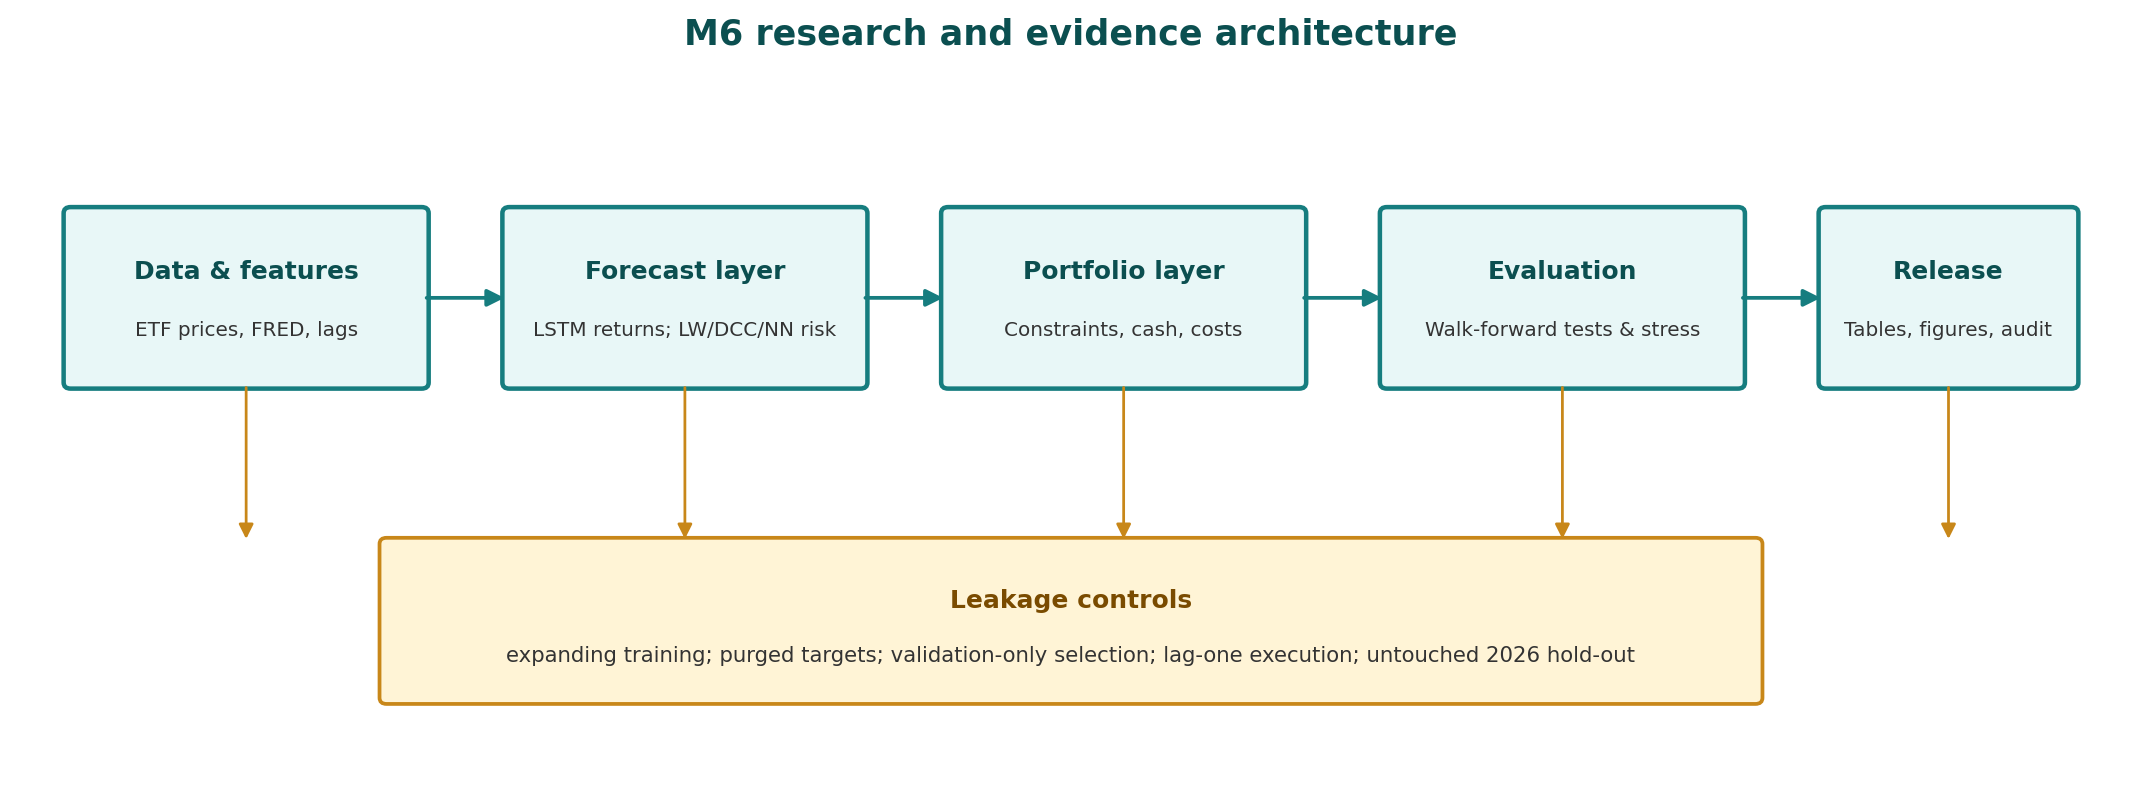

In [5]:
# System architecture diagram: generated, displayed inline, and saved with the other figures.
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import Image, display

fig_dir = Path(OUT) / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
arch_path = fig_dir / "architecture_diagram.png"
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.set_xlim(0, 12); ax.set_ylim(0, 4.4); ax.axis("off")
boxes = [
    (0.3, 2.5, 2.0, 1.1, "Data & features", "ETF prices, FRED, lags"),
    (2.8, 2.5, 2.0, 1.1, "Forecast layer", "LSTM returns; LW/DCC/NN risk"),
    (5.3, 2.5, 2.0, 1.1, "Portfolio layer", "Constraints, cash, costs"),
    (7.8, 2.5, 2.0, 1.1, "Evaluation", "Walk-forward tests & stress"),
    (10.3, 2.5, 1.4, 1.1, "Release", "Tables, figures, audit"),
]
for x,y,w,h,title,sub in boxes:
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.04",fc="#E8F7F7",ec="#167D7F",lw=1.8))
    ax.text(x+w/2,y+0.72,title,ha="center",va="center",fontsize=10,weight="bold",color="#0B4F50")
    ax.text(x+w/2,y+0.34,sub,ha="center",va="center",fontsize=8,color="#333333",wrap=True)
for a,b in zip(boxes[:-1],boxes[1:]):
    ax.add_patch(FancyArrowPatch((a[0]+a[2],3.05),(b[0],3.05),arrowstyle="-|>",mutation_scale=14,lw=1.5,color="#167D7F"))
ax.add_patch(FancyBboxPatch((2.1,0.45),7.8,1.0,boxstyle="round,pad=0.04",fc="#FFF4D6",ec="#C88719",lw=1.5))
ax.text(6.0,1.08,"Leakage controls",ha="center",va="center",fontsize=10,weight="bold",color="#7A4B00")
ax.text(6.0,0.72,"expanding training; purged targets; validation-only selection; lag-one execution; untouched 2026 hold-out",ha="center",va="center",fontsize=8.5,color="#333333")
for x in [1.3,3.8,6.3,8.8,11.0]:
    ax.add_patch(FancyArrowPatch((x,2.5),(x,1.45),arrowstyle="-|>",mutation_scale=12,lw=1.1,color="#C88719"))
fig.suptitle("M6 research and evidence architecture",fontsize=14,weight="bold",color="#0B4F50")
fig.tight_layout(); fig.savefig(arch_path,dpi=180,bbox_inches="tight"); plt.close(fig)
display(Image(filename=str(arch_path)))

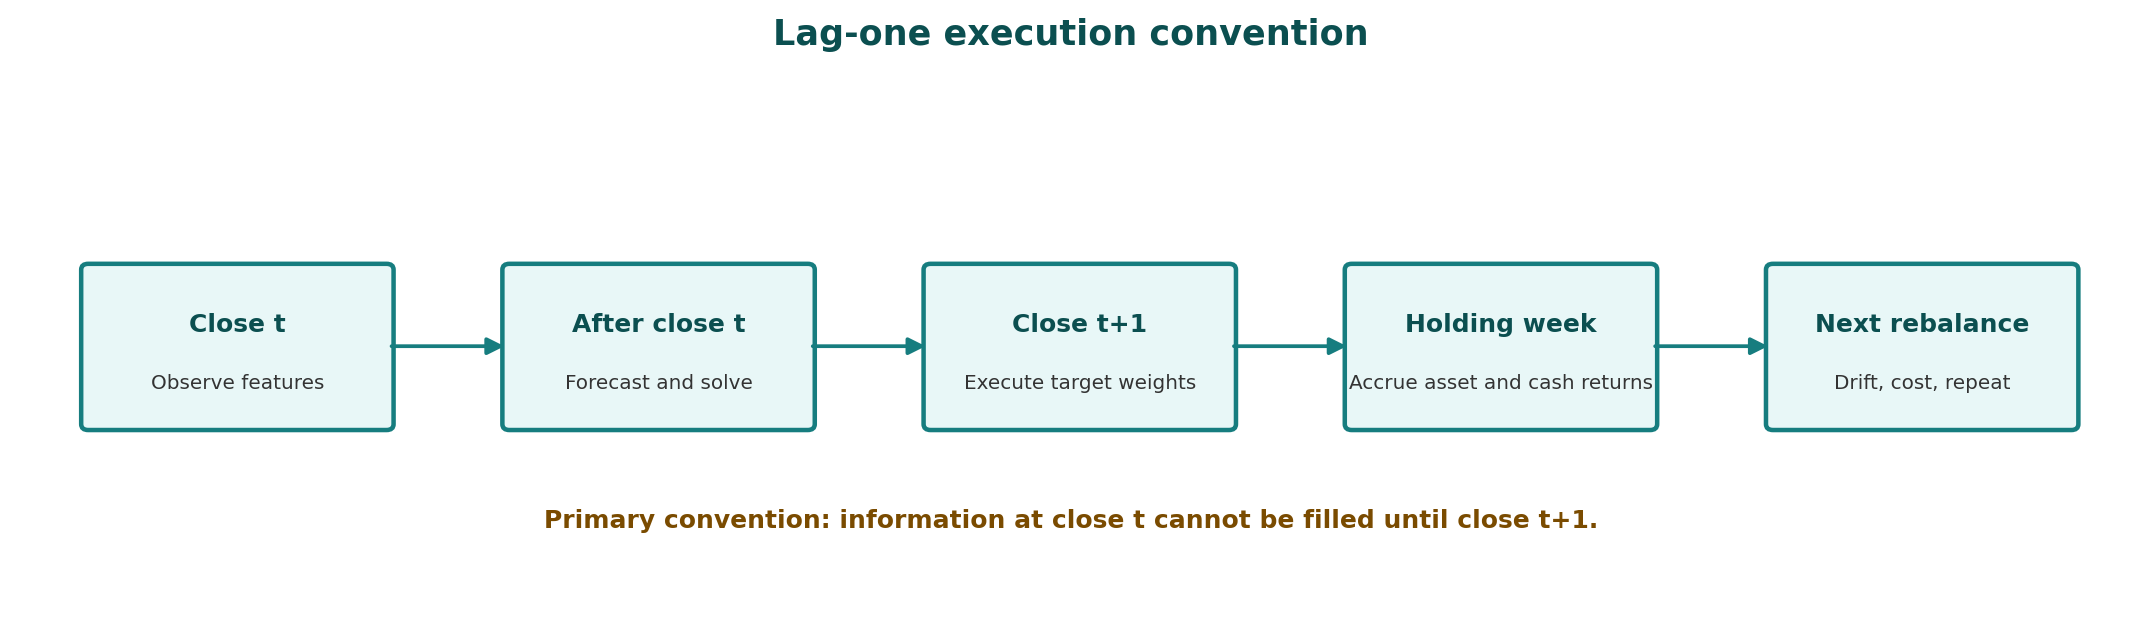

In [6]:
# Execution-timing diagram: generated, displayed inline, and saved with the other figures.
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import Image, display

fig_dir = Path(OUT) / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
timing_path = fig_dir / "timing_diagram.png"
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.set_xlim(0, 12); ax.set_ylim(0, 3.5); ax.axis("off")
steps = [
    (0.4, "Close t", "Observe features"),
    (2.8, "After close t", "Forecast and solve"),
    (5.2, "Close t+1", "Execute target weights"),
    (7.6, "Holding week", "Accrue asset and cash returns"),
    (10.0, "Next rebalance", "Drift, cost, repeat"),
]
for x,title,sub in steps:
    ax.add_patch(FancyBboxPatch((x,1.25),1.7,1.05,boxstyle="round,pad=0.04",fc="#E8F7F7",ec="#167D7F",lw=1.8))
    ax.text(x+0.85,1.93,title,ha="center",va="center",fontsize=10,weight="bold",color="#0B4F50")
    ax.text(x+0.85,1.53,sub,ha="center",va="center",fontsize=8,color="#333333",wrap=True)
for (x,_,_),(nx,_,_) in zip(steps[:-1],steps[1:]):
    ax.add_patch(FancyArrowPatch((x+1.7,1.78),(nx,1.78),arrowstyle="-|>",mutation_scale=14,lw=1.5,color="#167D7F"))
ax.text(6,0.55,"Primary convention: information at close t cannot be filled until close t+1.",ha="center",fontsize=10,weight="bold",color="#7A4B00")
fig.suptitle("Lag-one execution convention",fontsize=14,weight="bold",color="#0B4F50")
fig.tight_layout(); fig.savefig(timing_path,dpi=180,bbox_inches="tight"); plt.close(fig)
display(Image(filename=str(timing_path)))

## 2. Data

Adjusted closes for the nine Select Sector SPDR ETFs and SPY come from Yahoo Finance. DGS3MO, DGS10, T10Y3M and VIXCLS come from FRED. The audit table counts missing days per fund and checks whether they fall on NYSE holidays (peer point 5.3).

In [7]:
data = store.stage("01_data", lambda: M.stage_data(cfg))
print(data["prices"].index.min().date(), "to", data["prices"].index.max().date(), data["prices"].shape)
data["missing_audit"]

[01_data] loaded from checkpoint
1998-12-22 to 2026-10-01 (6986, 10)


,ticker,missing_days,missing_on_nyse_holiday,dates
0,XLB,0,0,
1,XLE,0,0,
2,XLF,0,0,
3,XLI,0,0,
4,XLK,0,0,
5,XLP,0,0,
6,XLU,0,0,
7,XLV,0,0,
8,XLY,0,0,
9,SPY,0,0,


## 3. Features and targets

Each asset gets lagged returns (1, 2, 5, 10 and 20 days), plus rolling volatility and momentum over 5, 20 and 60 days. Two market terms and the FRED series are added on top. Every macro series is lagged by its release delay (peer point 5.2). The target is the forward five-day log return. Scalers are fitted on the training rows of each refit only.

In [8]:
X, y, lr, macro_table = M.make_features(data["prices"], data["macro"], cfg)
print("feature matrix", X.shape, "| first usable date", X.index.min().date())
macro_table

feature matrix (6830, 109) | first usable date 1999-03-22


,series,frequency,release_lag_days,source
0,DGS3MO,daily,1,FRED
1,DGS10,daily,1,FRED
2,T10Y3M,daily,1,FRED
3,VIXCLS,daily,1,FRED


## 4. LSTM forecasts

Each forecast year uses a network trained on everything up to the previous 31 December. The last five rows before the boundary are dropped, because their targets cross it. Early stopping monitors the final 10% of the training window, never the forecast year (peer point 5.4).

- **2004, 2005, 2006:** validation-fold forecasts. These are the only data the M6 extensions may be chosen on.
- **2007–2025:** the test block.
- **2026:** the hold-out.

In [9]:
yrs = None if not QUICK_CHECK else [2004, 2005, 2006, 2007, 2008]
fc = store.stage("02_return_forecasts_seed42", lambda: M.stage_forecasts(X, y, cfg, "ret", 42, yrs))
lstm_mu, fit_log = fc
fit_log.tail()

[02_return_forecasts_seed42] loaded from checkpoint


,kind,seed,year,stopped_epoch,seconds
18,ret,42,2022,29,6.2
19,ret,42,2023,28,5.7
20,ret,42,2024,29,6.1
21,ret,42,2025,26,5.7
22,ret,42,2026,0,6.3


In [10]:
nn_sig = None
if RUN_COV_NET:
    nn_sig, cov_log = store.stage("03_cov_forecasts", lambda: M.stage_forecasts(X, y, cfg, "cov", 42,
                                  [y_ for y_ in range(2007, 2027)] if not QUICK_CHECK else [2007, 2008]))
seed_mu = {}
if RUN_SEED_ROBUSTNESS and not QUICK_CHECK:
    for s in cfg["robust_seeds"]:
        seed_mu[s] = store.stage(f"02_return_forecasts_seed{s}",
                                 lambda s=s: M.stage_forecasts(X, y, cfg, "ret", s, list(range(2007, 2026))))[0]

[03_cov_forecasts] loaded from checkpoint
[02_return_forecasts_seed7] loaded from checkpoint
[02_return_forecasts_seed2026] loaded from checkpoint


## 5. Covariance forecasts (five-day units)

Ledoit–Wolf uses a trailing 252-day window. DCC-GARCH(1,1) is re-estimated each January and filtered daily inside the year. The neural covariance comes from the log-Cholesky network. Because λ = 1, the hybrid equals Ledoit–Wolf, so the neural matrix is used only in the λ = 0 diagnostic.

In [11]:
all_dates = M.rebalance_dates(data["prices"].index, "2004-01-01", cfg["holdout"][1])
sig_lw = store.stage("04_cov_lw", lambda: M.lw_cov(lr, all_dates, cfg["lw_window"]))
dcc_out = store.stage("04_cov_dcc", lambda: M.dcc_cov(lr, all_dates[all_dates >= "2007-01-01"]))
sigmas = {"lw": sig_lw, "dcc": dcc_out[0]}
if nn_sig:
    sigmas["nn"] = nn_sig
dcc_out[1]

[04_cov_lw] loaded from checkpoint
[04_cov_dcc] loaded from checkpoint


,year,dcc_a,dcc_b,persistence,mean_garch_persistence
0,2007,0.016208,0.969656,0.985864,0.989705
1,2008,0.012960,0.964928,0.977888,0.986122
2,2009,0.017000,0.951148,0.968148,0.988490
3,2010,0.015963,0.964158,0.980121,0.988726
4,2011,0.019067,0.964153,0.983220,0.988804
5,2012,0.022354,0.965396,0.987750,0.989391
6,2013,0.021089,0.965104,0.986193,0.986447
7,2014,0.023680,0.960085,0.983765,0.988049
8,2015,0.021853,0.957482,0.979335,0.977476
9,2016,0.027462,0.936917,0.964378,0.966579


## 6. Walk-forward backtest, 2007–2025

All strategies trade under the same rules:
- long-only on the nine ETFs plus cash;
- a 25% position cap and a 20% one-way turnover cap;
- a 10% ex-ante volatility ceiling, met by holding T-bills;
- 10 bps per side.

One-way turnover is half the sum of absolute weight changes, measured from drifted weights. When no portfolio meets every constraint, the strategy holds its drifted weights. EW risk-matched is equal weight scaled each week to the 10% ex-ante ceiling, with the remainder in cash.

In [12]:
bt = store.stage(f"05_backtest_{RUN_TAG}", lambda: M.stage_backtest(data, lstm_mu, sigmas, cfg, lag=PRIMARY_EXECUTION_LAG))
bt_same_close = store.stage("05_backtest_same_close_diagnostic_v2", lambda: M.stage_backtest(data, lstm_mu, sigmas, cfg, lag=0))
cfg0 = dict(cfg, cost_bps=0.0)
bt0 = store.stage(f"05_backtest_0bps_{RUN_TAG}", lambda: M.stage_backtest(data, lstm_mu, sigmas, cfg0, lag=PRIMARY_EXECUTION_LAG,
                  strategies=[v for v in M.M4_STRATEGIES if v.name in ("A = E (GMV, LW)", "GMV, DCC", "B = C (full)")]))
seed_bt = {}
for s, mu_s in seed_mu.items():
    seed_bt[s] = store.stage(f"05_backtest_seed{s}_{RUN_TAG}", lambda mu_s=mu_s: M.stage_backtest(
        data, mu_s, sigmas, cfg, lag=PRIMARY_EXECUTION_LAG, strategies=[v for v in M.M4_STRATEGIES if v.name == "B = C (full)"]))["B = C (full)"]
seed_bt[42] = bt["B = C (full)"]
pd.DataFrame([v["summary"] for v in bt.values()]).round(3)

  A = E (GMV, LW): Sharpe 0.522 (2s)
  EW: Sharpe 0.528 (0s)
  GMV, DCC: Sharpe 0.475 (2s)
  ERC: Sharpe 0.463 (3s)
  HRP: Sharpe 0.465 (0s)
  EW risk-matched: Sharpe 0.441 (0s)
  D = MVO-LW: Sharpe 0.390 (4s)
  LSTM + DCC: Sharpe 0.405 (7s)
  B = C (full): Sharpe 0.305 (5s)
  Momentum 60d: Sharpe 0.099 (4s)
[05_backtest_lag1_v3_inline] done in 28.7s
[05_backtest_same_close_diagnostic_v2] loaded from checkpoint
  A = E (GMV, LW): Sharpe 0.543 (2s)
  GMV, DCC: Sharpe 0.614 (2s)
  B = C (full): Sharpe 0.483 (5s)
[05_backtest_0bps_lag1_v3_inline] done in 9.8s
  B = C (full): Sharpe 0.424 (4s)
[05_backtest_seed7_lag1_v3_inline] done in 4.0s
  B = C (full): Sharpe 0.312 (4s)
[05_backtest_seed2026_lag1_v3_inline] done in 4.2s


,strategy,ann_return,ann_vol,sharpe,sortino,max_dd,calmar,turnover_wk,mean_cash,avg_holdings,pct_turnover_cap_binds,pct_vol_ceiling_binds,pct_infeasible,weeks
0,"A = E (GMV, LW)",0.068,0.108,0.522,0.698,-0.265,0.255,0.022,0.217,6.046,0.006,0.754,0.002,992
1,EW,0.101,0.187,0.528,0.758,-0.526,0.193,0.006,0.000,9.000,0.000,0.924,0.000,992
2,"GMV, DCC",0.061,0.105,0.475,0.628,-0.264,0.232,0.141,0.158,6.232,0.329,0.640,0.169,992
3,ERC,0.062,0.111,0.463,0.615,-0.277,0.224,0.012,0.286,9.000,0.004,0.861,0.000,992
4,HRP,0.062,0.109,0.465,0.618,-0.267,0.232,0.030,0.256,9.000,0.008,0.824,0.002,992
5,EW risk-matched,0.060,0.111,0.441,0.586,-0.273,0.220,0.012,0.326,9.000,0.004,0.920,0.000,992
6,D = MVO-LW,0.054,0.112,0.390,0.517,-0.268,0.202,0.032,0.310,4.168,0.007,0.957,0.000,992
7,LSTM + DCC,0.057,0.116,0.405,0.584,-0.326,0.176,0.174,0.322,3.998,0.761,0.626,0.053,992
8,B = C (full),0.042,0.104,0.305,0.412,-0.288,0.147,0.178,0.371,3.714,0.769,0.677,0.010,992
9,Momentum 60d,0.020,0.097,0.099,0.126,-0.246,0.083,0.127,0.388,3.366,0.392,0.717,0.000,992


### Reconstruction check against the submitted M4 Table 3

This version rebuilds the pipeline from the M4 specification. The table below compares each strategy's Sharpe ratio and maximum drawdown with the numbers we submitted. Large gaps mean a design detail differs from the M4 code, and they should be resolved before the report cites any new number.

In [13]:
m4 = pd.DataFrame({
  "strategy": ["A = E (GMV, LW)", "EW", "GMV, DCC", "ERC", "HRP", "EW risk-matched", "D = MVO-LW", "LSTM + DCC", "B = C (full)"],
  "m4_sharpe": [0.597, 0.535, 0.534, 0.485, 0.475, 0.464, 0.397, 0.317, 0.265],
  "m4_max_dd": [-0.265, -0.570, -0.315, -0.267, -0.262, -0.272, -0.290, -0.222, -0.254],
  "m4_cash":   [0.171, 0.0, 0.121, 0.216, 0.213, 0.316, 0.258, 0.357, 0.395]})
now = pd.DataFrame([v["summary"] for v in bt.values()])[["strategy", "sharpe", "max_dd", "mean_cash"]]
chk = m4.merge(now, on="strategy", how="left")
chk["d_sharpe"] = chk["sharpe"] - chk["m4_sharpe"]
chk["d_max_dd"] = chk["max_dd"] - chk["m4_max_dd"]
store.table(chk, "m4_reconstruction_check")
chk.round(3)

,strategy,m4_sharpe,m4_max_dd,m4_cash,sharpe,max_dd,mean_cash,d_sharpe,d_max_dd
0,"A = E (GMV, LW)",0.597,-0.265,0.171,0.522,-0.265,0.217,-0.075,-0.000
1,EW,0.535,-0.570,0.000,0.528,-0.526,0.000,-0.007,0.044
2,"GMV, DCC",0.534,-0.315,0.121,0.475,-0.264,0.158,-0.059,0.051
3,ERC,0.485,-0.267,0.216,0.463,-0.277,0.286,-0.022,-0.010
4,HRP,0.475,-0.262,0.213,0.465,-0.267,0.256,-0.010,-0.005
5,EW risk-matched,0.464,-0.272,0.316,0.441,-0.273,0.326,-0.023,-0.001
6,D = MVO-LW,0.397,-0.290,0.258,0.390,-0.268,0.310,-0.007,0.022
7,LSTM + DCC,0.317,-0.222,0.357,0.405,-0.326,0.322,0.088,-0.104
8,B = C (full),0.265,-0.254,0.395,0.305,-0.288,0.371,0.040,-0.034


## 7. Tests on the test block

In [14]:
T = store.stage(f"06_tests_{RUN_TAG}", lambda: M.stage_tests(bt, data, lstm_mu, sigmas, cfg, zero_cost_bt=bt0, seed_bt=seed_bt))
for k, v in T.items():
    print("\n==", k); display(v.round(4))

[06_tests_lag1_v3_inline] done in 0.6s

== metrics_test


,strategy,ann_return,ann_vol,sharpe,sortino,max_dd,calmar,turnover_wk,mean_cash,avg_holdings,pct_turnover_cap_binds,pct_vol_ceiling_binds,pct_infeasible,weeks,calmar_rank,sharpe_rank
0,"A = E (GMV, LW)",0.0678,0.1075,0.5217,0.6983,-0.2653,0.2553,0.0222,0.2173,6.0464,0.0060,0.7540,0.0020,992,1,2
1,EW,0.1015,0.1875,0.5281,0.7578,-0.5256,0.1931,0.0061,0.0000,9.0000,0.0000,0.9244,0.0000,992,7,1
2,"GMV, DCC",0.0614,0.1049,0.4746,0.6283,-0.2640,0.2325,0.1406,0.1580,6.2319,0.3286,0.6401,0.1694,992,2,3
3,ERC,0.0622,0.1106,0.4628,0.6149,-0.2770,0.2244,0.0124,0.2857,9.0000,0.0040,0.8609,0.0000,992,4,5
4,HRP,0.0619,0.1093,0.4650,0.6181,-0.2671,0.2318,0.0299,0.2555,9.0000,0.0081,0.8236,0.0020,992,3,4
5,EW risk-matched,0.0599,0.1114,0.4411,0.5859,-0.2727,0.2195,0.0119,0.3257,9.0000,0.0040,0.9204,0.0000,992,5,6
6,D = MVO-LW,0.0540,0.1117,0.3900,0.5168,-0.2675,0.2017,0.0316,0.3103,4.1683,0.0071,0.9567,0.0000,992,6,8
7,LSTM + DCC,0.0573,0.1160,0.4055,0.5840,-0.3259,0.1757,0.1738,0.3220,3.9980,0.7611,0.6260,0.0534,992,8,7
8,B = C (full),0.0424,0.1038,0.3050,0.4123,-0.2878,0.1474,0.1775,0.3714,3.7137,0.7692,0.6774,0.0101,992,9,9
9,Momentum 60d,0.0204,0.0973,0.0994,0.1257,-0.2456,0.0831,0.1269,0.3876,3.3659,0.3921,0.7167,0.0000,992,10,10



== sharpe_tests_h1


,comparison,sharpe_1,sharpe_2,diff,se,z,p_two_sided,n,pw_block,block,boot_median,boot_lo95,boot_hi95,p_holm
0,C vs EW,0.3051,0.5283,-0.2232,0.1088,-2.0516,0.0402,992,4.3222,4,-0.2212,-0.4330,-0.0042,0.1206
1,C vs D = MVO-LW,0.3051,0.3902,-0.0851,0.1106,-0.7695,0.4416,992,2.0775,2,-0.0825,-0.3115,0.1517,0.4416
2,C vs ERC,0.3051,0.4630,-0.1579,0.0928,-1.7015,0.0888,992,1.6865,2,-0.1559,-0.3324,0.0395,0.1777



== h3_stress_regression


,comparison,stress_vol_threshold,n_weeks,n_stress_weeks,alpha_weekly,beta_stress_weekly,beta_se,t_stat,p_one_sided_beta_gt_0,p_two_sided,nw_lags
0,C minus EW,0.2264,992,154,-0.0013,-0.0003,0.0019,-0.1350,0.5537,0.8926,6
1,C minus EW risk-matched,0.2264,992,154,-0.0004,0.0007,0.0006,1.1877,0.1176,0.2353,6


... (10 outputs left out)


== seed_sharpe


,seed,sharpe_C,max_dd_C
0,7,0.4242,-0.2740
1,2026,0.3123,-0.2712
2,42,0.3050,-0.2878



== ex_infeasible


,strategy,weeks_kept,sharpe_all,sharpe_ex_infeasible
0,"A = E (GMV, LW)",990,0.5217,0.5243
1,EW,992,0.5281,0.5281
2,"GMV, DCC",824,0.4746,0.3867
3,ERC,992,0.4628,0.4628
4,HRP,990,0.4650,0.5760
5,EW risk-matched,992,0.4411,0.4411
6,D = MVO-LW,992,0.3900,0.3900
7,LSTM + DCC,939,0.4055,0.3165
8,B = C (full),982,0.3050,0.2755
9,Momentum 60d,992,0.0994,0.0994


## 8. Extensions chosen on validation only (instructor point 2)

Every one of the 21 variants is scored on the 2004, 2005 and 2006 folds. The variant with the highest mean net Sharpe ratio, plus the best variant in each family, is frozen with a time stamp before any test-period number is computed.

In [15]:
ext = store.stage(f"07_extensions_{RUN_TAG}", lambda: M.stage_extensions(data, lstm_mu, sigmas, cfg, n_jobs=N_JOBS, lag=PRIMARY_EXECUTION_LAG))
print("Frozen choices:", ext["chosen"], "at", ext["frozen_at"])
display(ext["leaderboard"].round(4)); display(ext["test_results"].round(4)); display(ext["deflated_sharpe"].round(4))

[07_extensions_lag1_v3_inline] done in 49.6s
Frozen choices: {'overall': 'RB_every4', 'MV': 'MV_g10', 'TP': 'TP_k10bp', 'SM': 'SM_a0.25', 'RB': 'RB_every4', 'MVTP': 'MVTP_g10_k10bp'} at 2026-10-25T23:54:45


,variant,objective,gamma,kappa,smooth,every,sharpe_2004,turnover_2004,sharpe_2005,turnover_2005,sharpe_2006,turnover_2006,mean_val_sharpe,selection_direction,selected_overall
0,RB_every4,linear,0.0,0.0000,1.00,4,0.9820,0.0495,0.7140,0.0498,1.0558,0.0500,0.9173,max,True
1,RB_every2,linear,0.0,0.0000,1.00,2,0.4477,0.0921,1.1187,0.0973,0.7684,0.0954,0.7783,max,False
2,MVTP_g10_k10bp,meanvar,10.0,0.0010,1.00,1,0.3101,0.1541,1.0660,0.1832,0.8672,0.1842,0.7478,max,False
3,MV_g10,meanvar,10.0,0.0000,1.00,1,0.2965,0.1571,1.0597,0.1866,0.8825,0.1862,0.7462,max,False
4,MVTP_g10_k20bp,meanvar,10.0,0.0020,1.00,1,0.3176,0.1503,1.0524,0.1802,0.8407,0.1799,0.7369,max,False
5,MV_g25,meanvar,25.0,0.0000,1.00,1,0.3300,0.1568,1.0222,0.1905,0.8292,0.1859,0.7271,max,False
6,MVTP_g25_k10bp,meanvar,25.0,0.0010,1.00,1,0.3397,0.1541,1.0234,0.1886,0.8172,0.1838,0.7268,max,False
7,SM_a0.25,linear,0.0,0.0000,0.25,1,0.5356,0.0638,1.1773,0.1069,0.4554,0.1273,0.7228,max,False
8,SM_a0.1,linear,0.0,0.0000,0.10,1,0.5347,0.0385,0.9394,0.0625,0.6865,0.0887,0.7202,max,False
9,SM_a0.5,linear,0.0,0.0000,0.50,1,0.4793,0.1014,1.0783,0.1440,0.6020,0.1423,0.7199,max,False


,run,strategy,ann_return,ann_vol,sharpe,sortino,max_dd,calmar,turnover_wk,mean_cash,avg_holdings,pct_turnover_cap_binds,pct_vol_ceiling_binds,pct_infeasible,weeks
0,baseline,C_linear_baseline,0.0424,0.1038,0.3050,0.4123,-0.2878,0.1474,0.1775,0.3714,3.7137,0.7692,0.6774,0.0101,992
1,chosen_overall,RB_every4,0.0380,0.1066,0.2600,0.3521,-0.2727,0.1395,0.0487,0.3697,4.0766,0.2308,0.4234,0.0000,992
2,chosen_MV,MV_g10,0.0371,0.0984,0.2643,0.3530,-0.2766,0.1342,0.1777,0.4155,3.5101,0.7671,0.5202,0.0000,992
3,chosen_TP,TP_k10bp,0.0440,0.1055,0.3155,0.4344,-0.2893,0.1519,0.1688,0.3746,3.7087,0.7107,0.6704,0.0131,992
4,chosen_SM,SM_a0.25,0.0354,0.1012,0.2432,0.3247,-0.2682,0.1319,0.1085,0.3687,3.2994,0.3004,0.7671,0.0000,992
5,chosen_RB,RB_every4,0.0380,0.1066,0.2600,0.3521,-0.2727,0.1395,0.0487,0.3697,4.0766,0.2308,0.4234,0.0000,992
6,chosen_MVTP,MVTP_g10_k10bp,0.0365,0.0986,0.2577,0.3439,-0.2760,0.1321,0.1703,0.4134,3.5121,0.7127,0.5151,0.0000,992
7,baseline_same_close_diagnostic,C_linear_baseline,0.0452,0.1045,0.3292,0.4434,-0.2716,0.1664,0.1775,0.3716,3.7208,0.7651,0.6764,0.0101,992
8,chosen_same_close_diagnostic,RB_every4,0.0401,0.1018,0.2873,0.3821,-0.2385,0.1682,0.0488,0.3696,4.0887,0.2308,0.4224,0.0000,992
9,momentum_linear,MOM,0.0204,0.0973,0.0994,0.1257,-0.2456,0.0831,0.1269,0.3876,3.3659,0.3921,0.7167,0.0000,992


,sharpe_annual,sr0_annual,n_trials,skew,kurtosis,deflated_sharpe_prob
0,0.26,0.1117,21,-0.7205,17.6411,0.738


## 9. Hold-out, January to September 2026

In [16]:
ho = store.stage(f"08_holdout_{RUN_TAG}", lambda: M.stage_holdout(data, lstm_mu, sigmas, ext["chosen"]["overall"], cfg, lag=PRIMARY_EXECUTION_LAG))
ho.round(4)

[08_holdout_lag1_v3_inline] done in 1.0s


,strategy,ann_return,ann_vol,sharpe,sortino,max_dd,calmar,turnover_wk,mean_cash,avg_holdings,pct_turnover_cap_binds,pct_vol_ceiling_binds,pct_infeasible,weeks
0,"A = E (GMV, LW)",0.1102,0.0676,1.0153,1.4988,-0.0472,2.3362,0.0410,0.1089,6.8462,0.0769,0.3077,0.0000,39
1,EW,0.1241,0.0816,1.0055,1.6327,-0.0570,2.1768,0.0089,0.0000,9.0000,0.0000,0.4872,0.0000,39
2,"GMV, DCC",0.0662,0.0649,0.4306,0.6199,-0.0427,1.5483,0.1658,0.1512,7.4615,0.4872,0.7436,0.2051,39
3,ERC,0.0947,0.0625,0.8679,1.2856,-0.0435,2.1767,0.0329,0.1333,9.0000,0.0769,0.3333,0.0000,39
4,HRP,0.0485,0.0711,0.1636,0.2235,-0.0575,0.8439,0.0461,0.1195,9.0000,0.0769,0.3077,0.0000,39
5,EW risk-matched,0.0919,0.0646,0.8006,1.2839,-0.0450,2.0415,0.0321,0.1525,9.0000,0.0769,0.4103,0.0000,39
6,D = MVO-LW,0.1011,0.0701,0.8640,1.2524,-0.0521,1.9416,0.0668,0.1264,6.1282,0.1538,0.9487,0.0000,39
7,LSTM + DCC,0.0543,0.0469,0.3362,0.5182,-0.0341,1.5937,0.1918,0.5039,3.3077,0.9231,0.3590,0.0000,39
8,B = C (full),0.0651,0.0514,0.5087,0.7878,-0.0337,1.9337,0.1931,0.4387,3.6667,0.8974,0.3333,0.0000,39
9,Momentum 60d,0.1021,0.0842,0.7415,1.2046,-0.0400,2.5537,0.1496,0.2337,4.1282,0.5385,0.7179,0.0000,39


## 10. Figures, tables and the results workbook

The five result figures use one fixed colour per strategy, labelled axes, and consistent benchmark coverage. The architecture and timing diagrams above, every exported result table below, and all five figures are displayed inline and saved to the run directory.

**Primary execution convention:** 1-trading-day lag after the decision close.

### Saved result figures

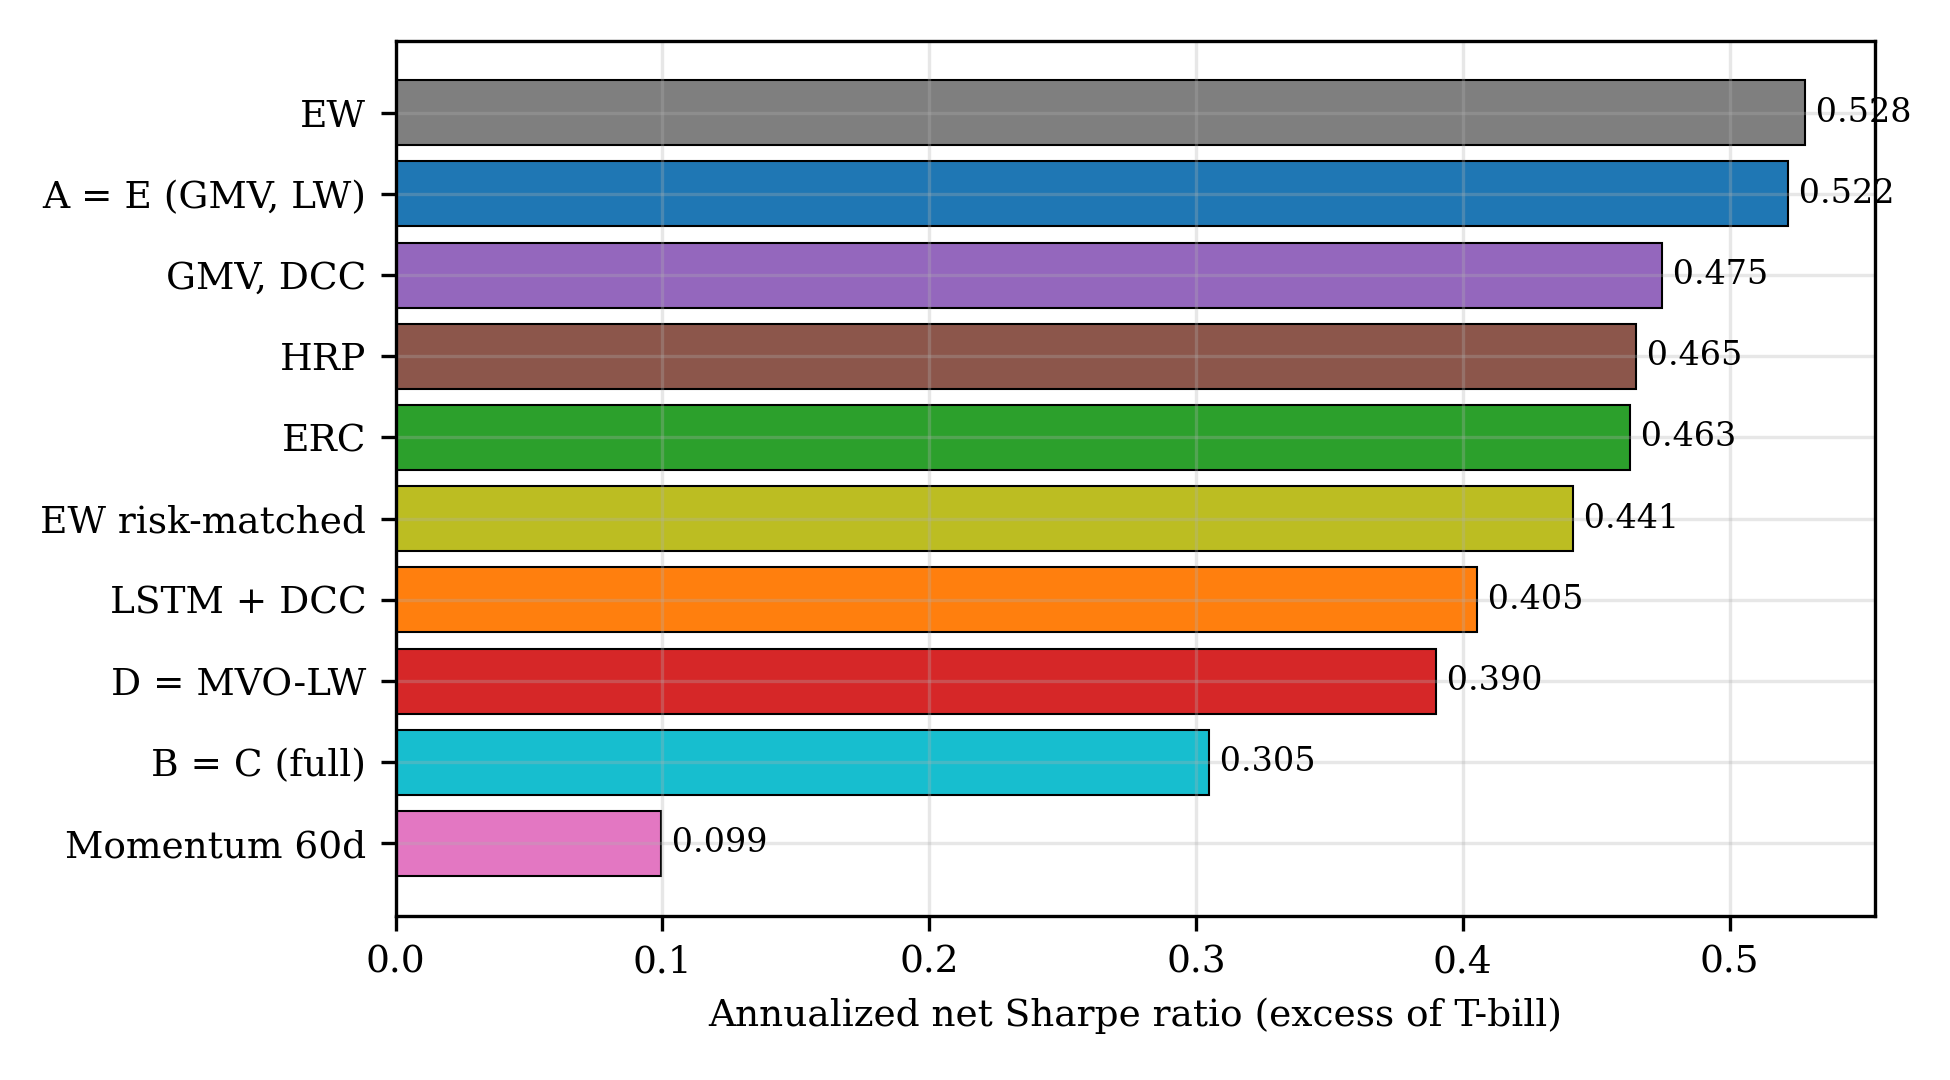

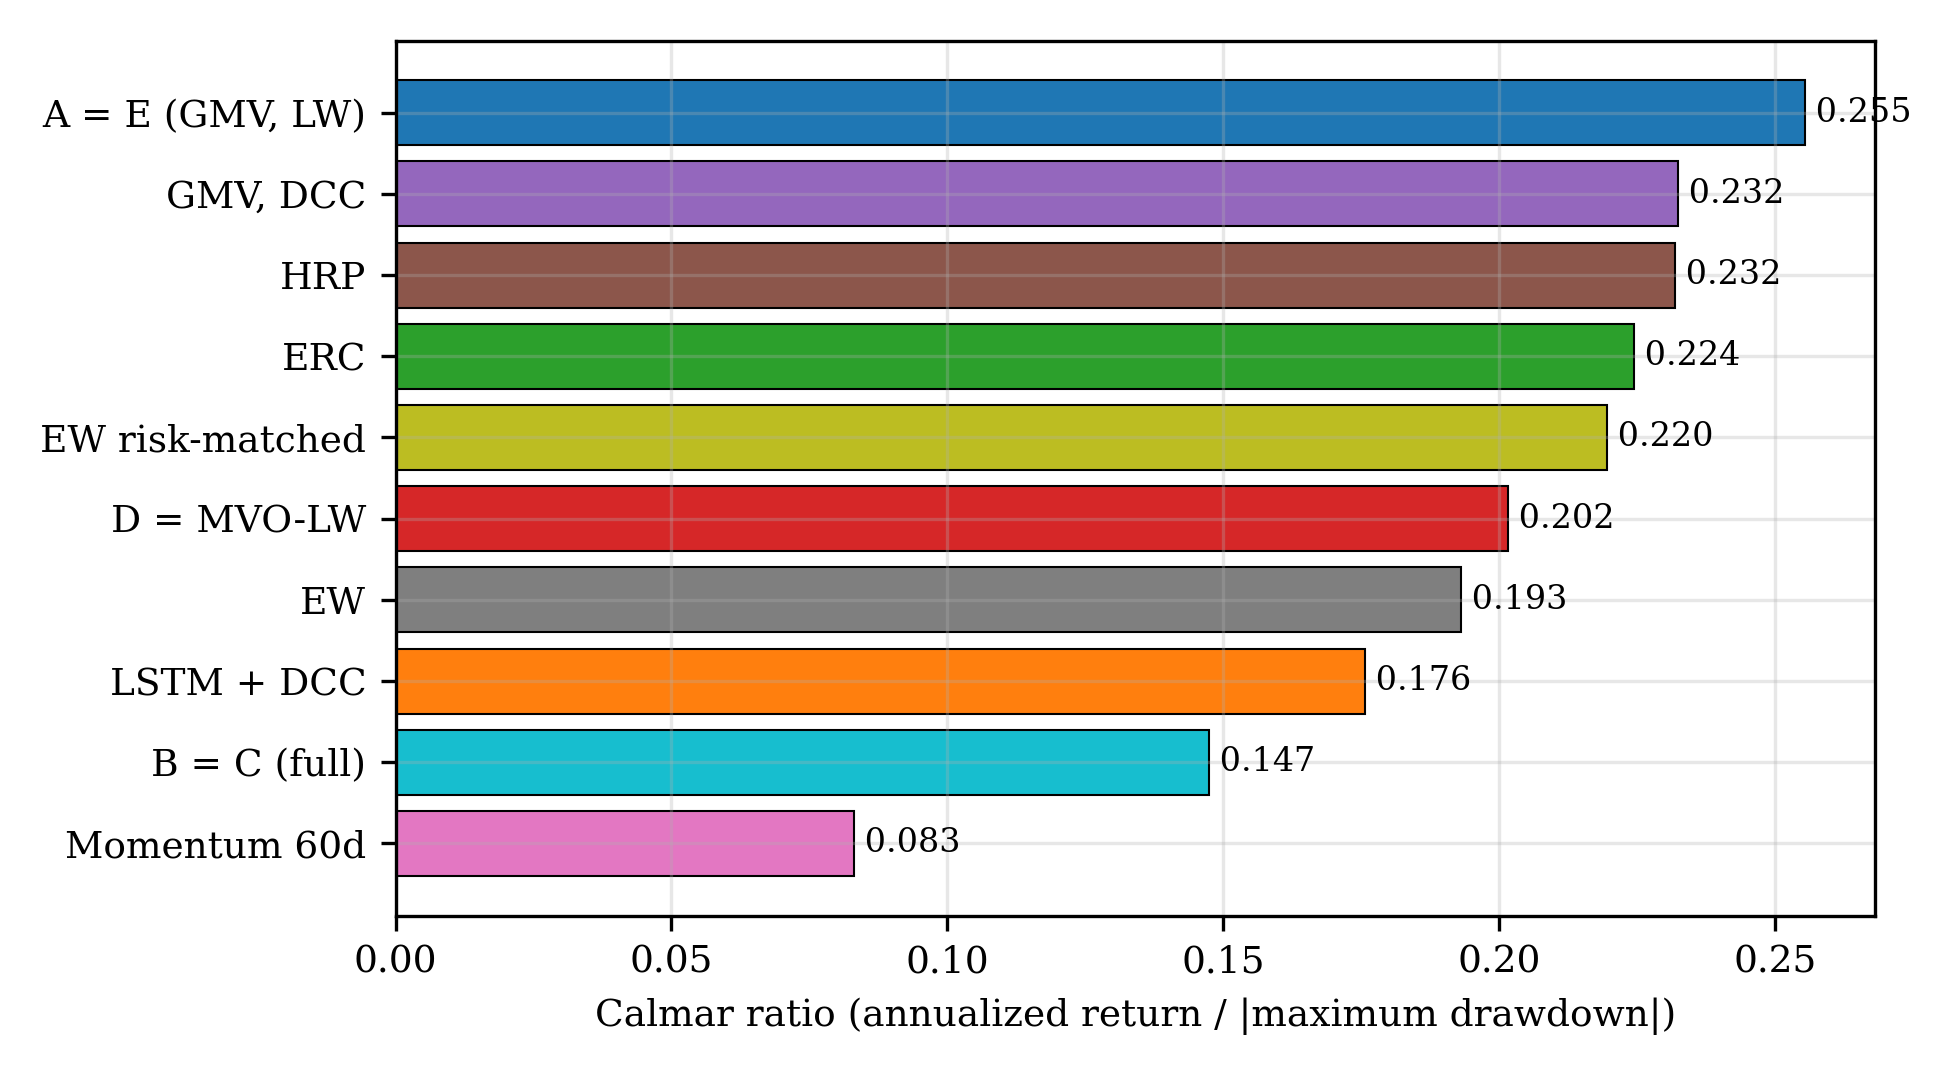

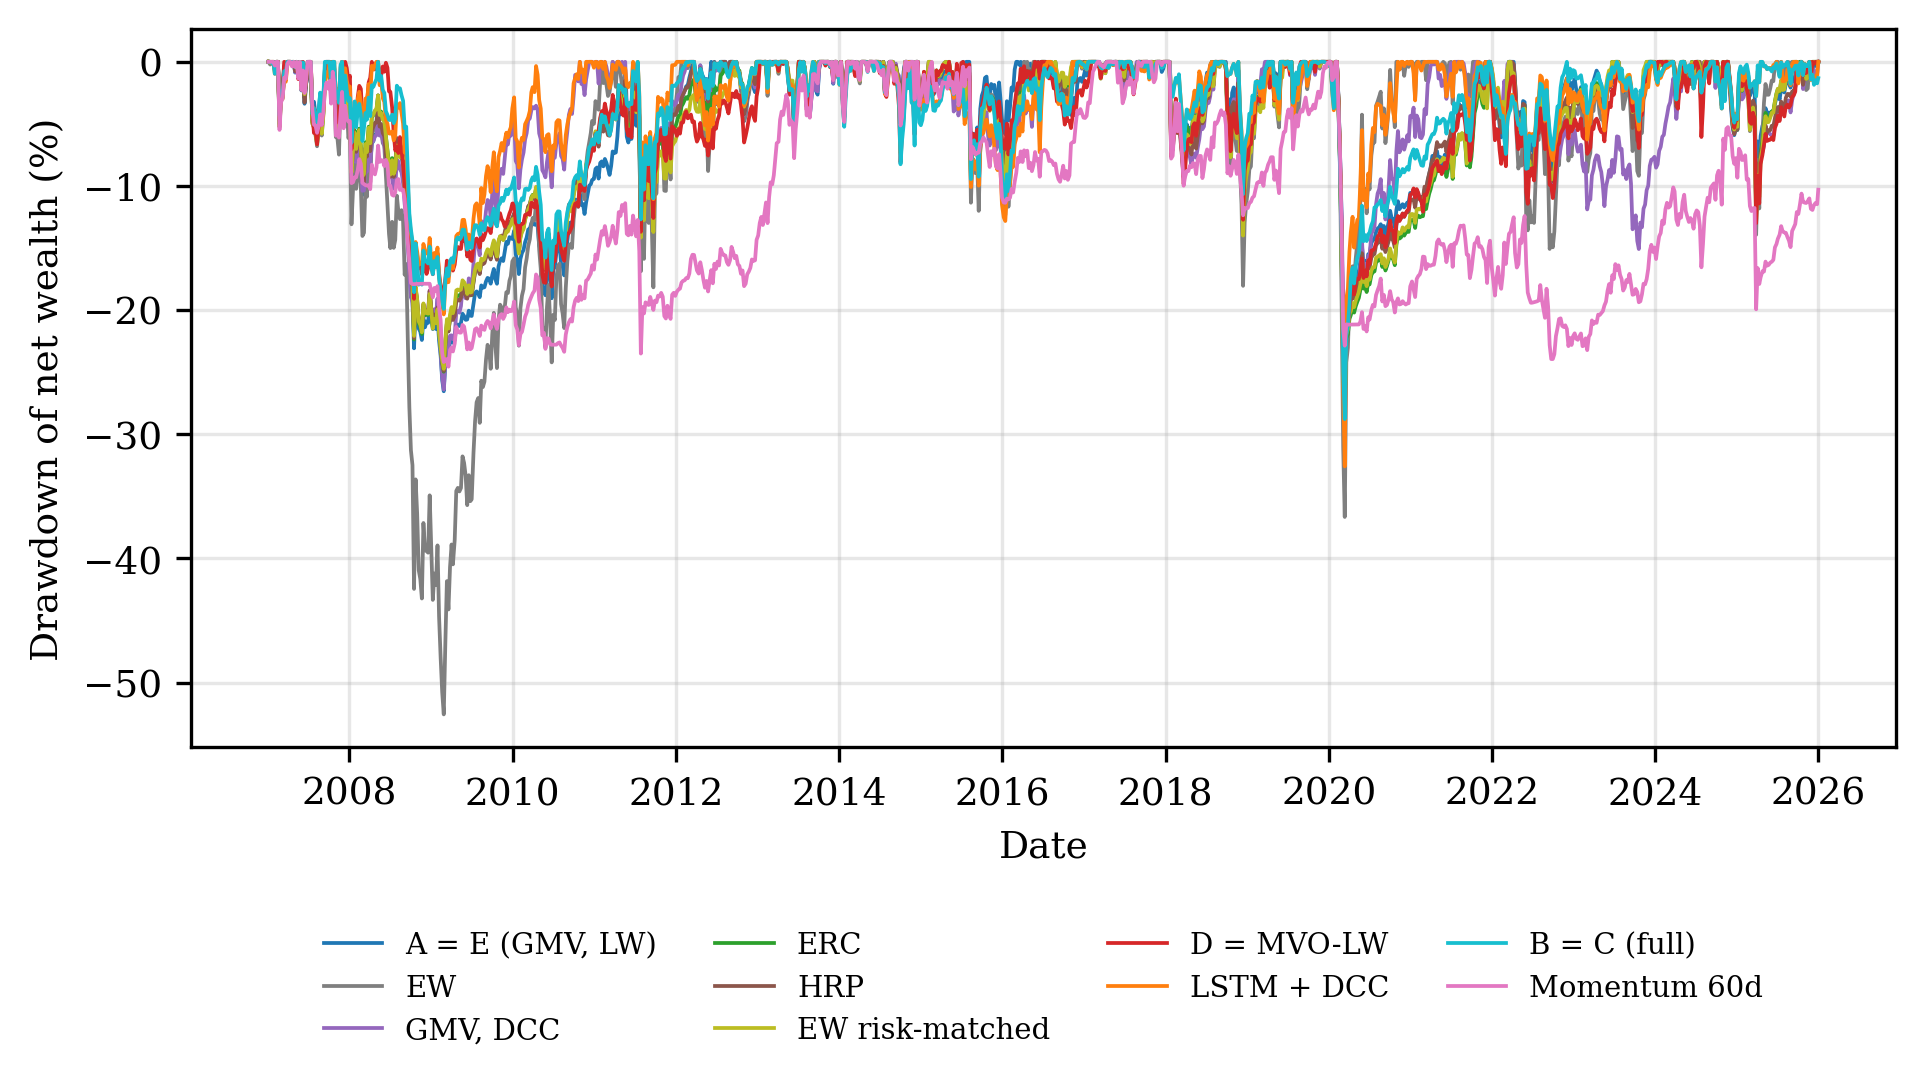

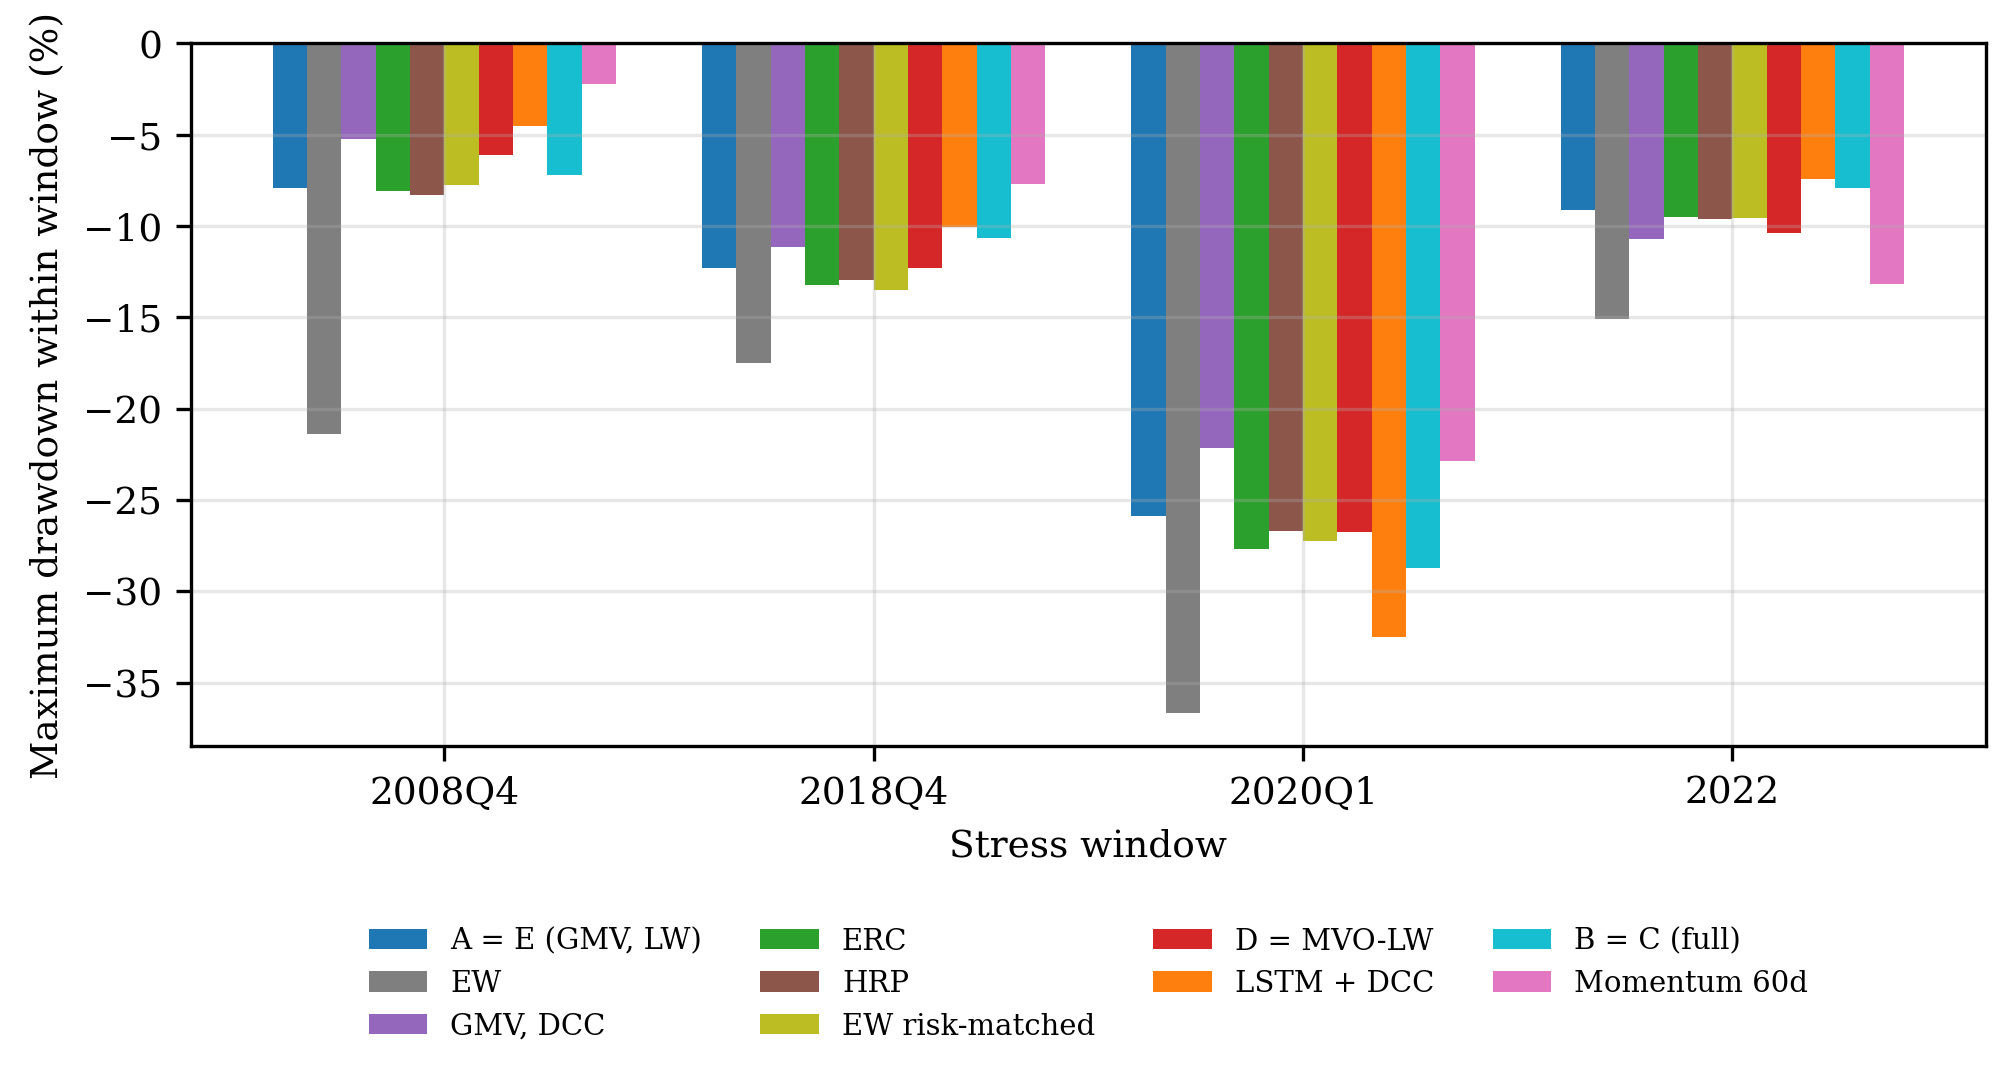

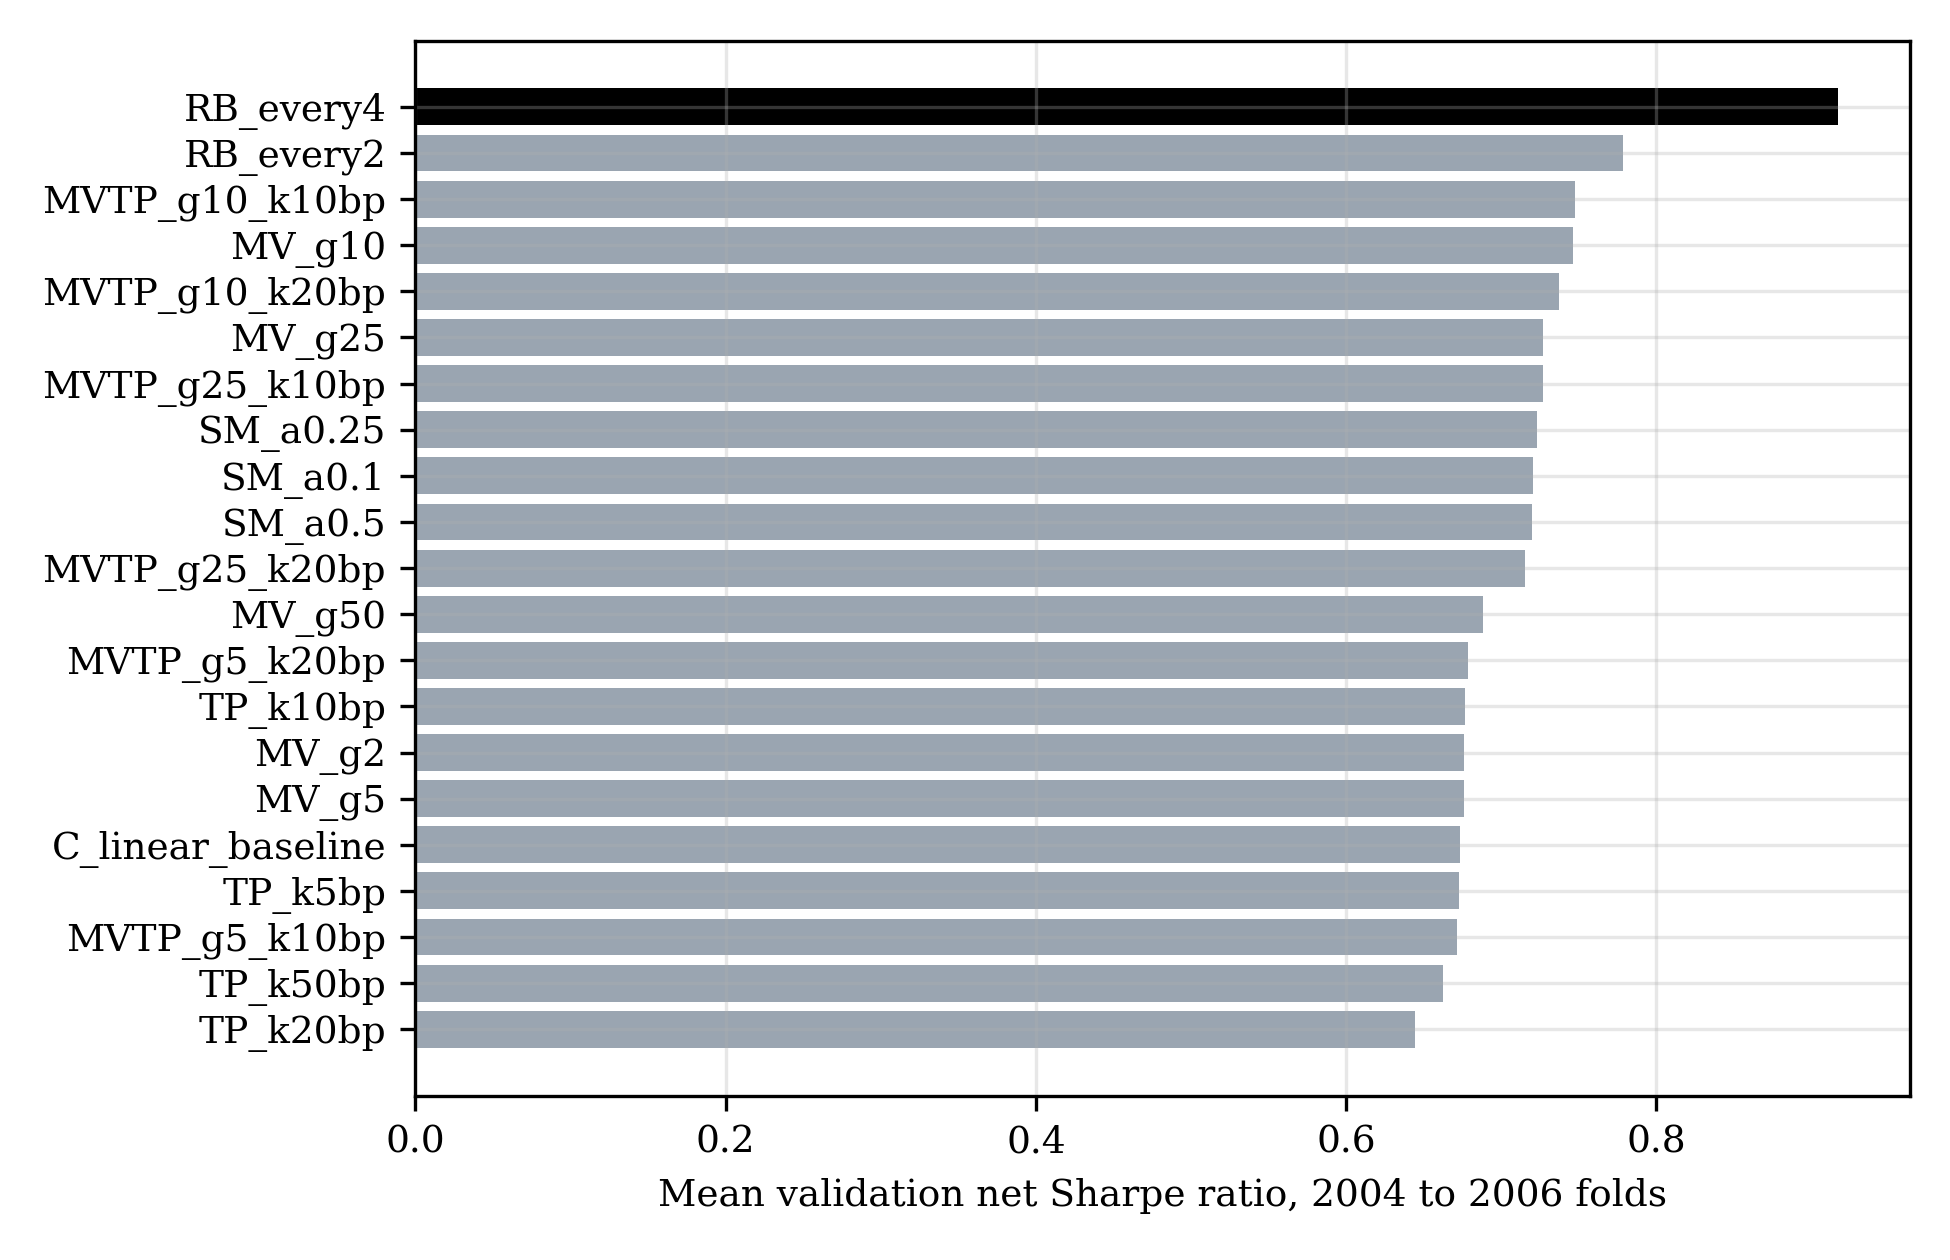

### Metrics Test

,strategy,ann_return,ann_vol,sharpe,sortino,max_dd,calmar,turnover_wk,mean_cash,avg_holdings,pct_turnover_cap_binds,pct_vol_ceiling_binds,pct_infeasible,weeks,calmar_rank,sharpe_rank
0,"A = E (GMV, LW)",0.06775,0.10752,0.52172,0.69834,-0.26535,0.25534,0.02225,0.21725,6.04637,0.00605,0.75403,0.00202,992,1,2
1,EW,0.10148,0.18749,0.52808,0.75776,-0.52563,0.19307,0.00605,0.00000,9.00000,0.00000,0.92440,0.00000,992,7,1
2,"GMV, DCC",0.06138,0.10490,0.47456,0.62825,-0.26403,0.23246,0.14056,0.15795,6.23185,0.32863,0.64012,0.16935,992,2,3
3,ERC,0.06216,0.11062,0.46281,0.61487,-0.27697,0.22442,0.01244,0.28569,9.00000,0.00403,0.86089,0.00000,992,4,5
4,HRP,0.06192,0.10929,0.46500,0.61810,-0.26714,0.23181,0.02988,0.25555,9.00000,0.00806,0.82359,0.00202,992,3,4
5,EW risk-matched,0.05987,0.11135,0.44115,0.58593,-0.27270,0.21954,0.01187,0.32566,9.00000,0.00403,0.92036,0.00000,992,5,6
6,D = MVO-LW,0.05395,0.11171,0.39003,0.51682,-0.26755,0.20166,0.03159,0.31028,4.16835,0.00706,0.95665,0.00000,992,6,8
7,LSTM + DCC,0.05726,0.11601,0.40546,0.58400,-0.32589,0.17571,0.17382,0.32197,3.99798,0.76109,0.62601,0.05343,992,8,7
8,B = C (full),0.04243,0.10384,0.30498,0.41225,-0.28778,0.14744,0.17754,0.37144,3.71371,0.76915,0.67742,0.01008,992,9,9
9,Momentum 60d,0.02040,0.09728,0.09945,0.12566,-0.24557,0.08308,0.12691,0.38759,3.36593,0.39214,0.71673,0.00000,992,10,10


### Sharpe Tests H1

,comparison,sharpe_1,sharpe_2,diff,se,z,p_two_sided,n,pw_block,block,boot_median,boot_lo95,boot_hi95,p_holm
0,C vs EW,0.30513,0.52835,-0.22321,0.10880,-2.05164,0.04020,992,4.32224,4,-0.22118,-0.43303,-0.00418,0.12061
1,C vs D = MVO-LW,0.30513,0.39023,-0.08509,0.11059,-0.76947,0.44161,992,2.07752,2,-0.08253,-0.31149,0.15166,0.44161
2,C vs ERC,0.30513,0.46304,-0.15791,0.09280,-1.70153,0.08884,992,1.68651,2,-0.15591,-0.33237,0.03946,0.17769


### H3 Stress Regression

,comparison,stress_vol_threshold,n_weeks,n_stress_weeks,alpha_weekly,beta_stress_weekly,beta_se,t_stat,p_one_sided_beta_gt_0,p_two_sided,nw_lags
0,C minus EW,0.22638,992,154,-0.00125,-0.00026,0.00195,-0.13499,0.55368,0.89265,6
1,C minus EW risk-matched,0.22638,992,154,-0.00044,0.00067,0.00057,1.18766,0.11763,0.23525,6


... (35 outputs left out)

,strategy,ann_return,ann_vol,sharpe,sortino,max_dd,calmar,turnover_wk,mean_cash,avg_holdings,pct_turnover_cap_binds,pct_vol_ceiling_binds,pct_infeasible,weeks
0,"A = E (GMV, LW)",0.06966,0.10619,0.54378,0.72688,-0.26233,0.26556,0.02214,0.21724,6.04637,0.00605,0.75403,0.00202,992
1,EW,0.10078,0.17892,0.54167,0.76378,-0.52562,0.19173,0.00603,0.00000,9.00000,0.00000,0.92440,0.00000,992
2,"GMV, DCC",0.06326,0.10485,0.49165,0.66040,-0.25325,0.24980,0.14042,0.15791,6.23387,0.32964,0.63911,0.16935,992
3,ERC,0.06330,0.10608,0.48807,0.64956,-0.25368,0.24952,0.01219,0.28568,9.00000,0.00504,0.86089,0.00101,992
4,HRP,0.06293,0.10577,0.48585,0.64598,-0.24852,0.25324,0.02974,0.25555,9.00000,0.00706,0.82359,0.00202,992
5,EW risk-matched,0.06112,0.10532,0.47131,0.63057,-0.25169,0.24285,0.01167,0.32566,9.00000,0.00403,0.92036,0.00000,992
6,D = MVO-LW,0.05477,0.10691,0.40971,0.54646,-0.22748,0.24077,0.03110,0.31028,4.16935,0.00806,0.95665,0.00000,992
7,LSTM + DCC,0.05212,0.11174,0.37388,0.51073,-0.29523,0.17654,0.17562,0.32705,3.97480,0.76915,0.62399,0.04335,992
8,B = C (full),0.04519,0.10451,0.32915,0.44338,-0.27161,0.16638,0.17747,0.37159,3.72077,0.76512,0.67641,0.01008,992
9,Momentum 60d,0.02282,0.09253,0.12507,0.16073,-0.24164,0.09444,0.12673,0.38777,3.35081,0.38911,0.71774,0.00000,992


### Frozen Choices

,family,variant
0,overall,RB_every4
1,MV,MV_g10
2,TP,TP_k10bp
3,SM,SM_a0.25
4,RB,RB_every4
5,MVTP,MVTP_g10_k10bp
6,frozen_at,2026-10-25T23:54:45


Workbook: /content/drive/MyDrive/CAPSTONE_M6_RUN/M6_RESULTS_17863.xlsx


In [17]:
figs = M.make_figures(bt, T, ext, store, cfg)
from IPython.display import display, Markdown, Image
same_close_metrics = pd.DataFrame([v["summary"] for v in bt_same_close.values()])
timing_compare = T["metrics_test"][["strategy","sharpe","ann_return","max_dd","turnover_wk"]].merge(
    same_close_metrics[["strategy","sharpe","ann_return","max_dd","turnover_wk"]], on="strategy", suffixes=("_lag1","_same_close"))
tables = {**T, "validation_leaderboard": ext["leaderboard"], "extension_test": ext["test_results"],
          "deflated_sharpe": ext["deflated_sharpe"], "holdout_2026": ho, "dcc_parameters": dcc_out[1],
          "missing_day_audit": data["missing_audit"], "macro_features": macro_table,
          "forecast_fit_log": fit_log, "m4_reconstruction_check": chk,
          "execution_timing_compare": timing_compare, "metrics_same_close_diagnostic": same_close_metrics,
          "frozen_choices": pd.DataFrame([{"family": k, "variant": v} for k, v in ext["chosen"].items()] +
                                         [{"family": "frozen_at", "variant": ext["frozen_at"]}])}

display(Markdown(f"**Primary execution convention:** {PRIMARY_EXECUTION_LAG}-trading-day lag after the decision close."))
display(Markdown("### Saved result figures"))
for p in figs:
    display(Image(filename=str(p)))
for name, table in tables.items():
    display(Markdown("### " + name.replace("_", " ").title()))
    display(table.round(5))
    store.table(table, name)
meta = {"group": "17863", "milestone": "M6", "mode": "QUICK_CHECK (do not cite)" if QUICK_CHECK else "full",
        "started": str(RUN_STARTED), "finished": str(pd.Timestamp.now()), "gpu": str([g.name for g in gpus]),
        "tensorflow": tf.__version__, "cvxpy": M.HAVE_CVXPY, "execution_lag_days": PRIMARY_EXECUTION_LAG,
        "run_tag": RUN_TAG, "price_end": str(data["prices"].index.max().date())}
book = f"{OUT}/M6_RESULTS_17863.xlsx"
M.export_workbook(store, tables, meta, book)
log_md = "# M6 run log\n\n" + "\n".join(f"- {k}: {v}" for k, v in meta.items()) + "\n\n| stage | seconds |\n|---|---|\n" + \
         "\n".join(f"| {r['stage']} | {r['seconds']} |" for r in store.log)
open(f"{OUT}/m6_run_log.md", "w").write(log_md)
import shutil; shutil.make_archive(f"{OUT}/figures", "zip", f"{OUT}/figures")
print("Workbook:", book)

In [18]:
if ON_COLAB:
    from google.colab import files
    for f in ("M6_RESULTS_17863.xlsx", "m6_run_log.md", "figures.zip"):
        files.download(f"{OUT}/{f}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>